# Road Accident Severity Prediction — project walkthrough
**DSTT project · Tahir Ahmed Khan (25I-8025), Ahmed Qamar (25I-8049), Ali Raza (25I-8043)**

This notebook walks through the finished pipeline using the saved artefacts. The heavy steps
(training 144 models, GPU runs) are reproducible scripts in `scripts/` (see README); this notebook
only loads their outputs, so it runs in seconds.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
T, F = ROOT / "reports" / "tables", ROOT / "reports" / "figures"
pd.set_option("display.max_columns", 30, "display.width", 160, "display.precision", 4)

## 1. Data and splits
UK DfT STATS19 2023–2025, one row per collision. Target: Severe (fatal/serious) vs Slight.

In [2]:
display(pd.read_csv(T / "split_summary.csv"))
display(pd.read_csv(T / "data_quality.csv").head(8))

,split,rows,n_severe,severe_rate
0,fit,104258,24960,0.2394
1,tune,51241,12682,0.2475
2,cal,49686,12387,0.2493
3,test,101525,26644,0.2624


,metric,2023,2024,2025,all
0,rows,104258.0000,100927.0000,101525.0000,306710.0000
1,vehicle_rows,189815.0000,183514.0000,183948.0000,557277.0000
2,severe_rate,0.2394,0.2484,NaN,NaN
3,injury_based_share,0.5373,0.5875,0.8653,0.6624
4,ped_involved_share,0.1777,0.1829,0.1883,0.1829
5,missing_pct_hour,0.0000,0.0000,0.0000,0.0000
6,missing_pct_longitude,0.0100,0.0000,0.0000,0.0000
7,missing_pct_local_authority_ons_district,0.0000,0.0000,0.0000,0.0000


## 2. Leakage audit
Every raw column has exactly one decision (`src/data/schema.py`); tests enforce it.

In [3]:
audit = pd.read_csv(T / "leakage_audit.csv")
display(audit["decision"].value_counts().to_frame())
mask = audit["decision"].str.contains("leak|tier", regex=True)
display(audit[mask][["table", "name", "decision", "reason"]])

,count
decision,
keep,41
drop_other,26
drop_leakage,14
drop_id,12
tier_b,5
target,1
eval_only,1


,table,name,decision,reason
10,collision,number_of_casualties,drop_leakage,Injury-outcome count.
40,collision,enhanced_severity_collision,drop_leakage,Target-derived severity.
42,collision,collision_adjusted_severity_serious,drop_leakage,Target-derived adjustment weight.
43,collision,collision_adjusted_severity_slight,drop_leakage,Target-derived adjustment weight.
57,vehicle,skidding_and_overturning,tier_b,Crash mechanics / impact consequence (sensitiv...
58,vehicle,hit_object_in_carriageway,tier_b,Crash mechanics / impact consequence (sensitiv...
59,vehicle,vehicle_leaving_carriageway,tier_b,Crash mechanics / impact consequence (sensitiv...
60,vehicle,hit_object_off_carriageway,tier_b,Crash mechanics / impact consequence (sensitiv...
61,vehicle,first_point_of_impact,tier_b,Crash mechanics / impact consequence (sensitiv...
82,casualty,sex_of_casualty,drop_leakage,Injury composition (rows exist only for injured).


## 3. Exploratory analysis (2023–2024 only)

# Exploratory data analysis: key findings

Scope: STATS19 collisions in Great Britain. All severity (label) statistics use the 2023–2024
development years only (n = 205,185). The 2025 test year (n = 101,525) appears only in label-free
covariate views: reporting-system share and missingness. Rates are given with 95% Wilson
confidence intervals. The full table is in `reports/tables/eda_summary.csv`, and the scripts that
produce it are `scripts/02_eda.py` and `src/evaluation/eda.py`.

1. **Class balance.** The positive class (Fatal or Serious) makes up about one quarter of
   collisions: 23.9% [23.7, 24.2] in 2023 and 24.8% [24.6, 25.1] in 2024. Fatal collisions are
   rare (1.5% in both years), so the binary target is driven almost entirely by "Serious".
   The imbalance is moderate, at roughly 3:1
   (`figures/eda_01_class_balance.png`).

2. **Reporting-system drift.** The share of collisions recorded by injury-based systems
   (CRaSH/COPA) rose from 53.7% in 2023 to 58.8% in 2024 and then jumped to 86.5% in 2025.
   The monthly severe rate moved between about 22% and 28% over 2023–2024 and peaked in
   August 2024 (`figures/eda_02_monthly_trend_reporting.png`). Because the 2025 covariate mix
   lies far outside the development range, a shift in the prior and in calibration is expected
   on the test year.

3. **Recording system as a measurement effect.** Injury-based recording gives a much higher
   severe rate than legacy severity-based recording: 28.3% [28.0, 28.5] vs 19.4% [19.2, 19.7]
   over 2023–2024. Within each system the rate rose by only 0.5 percentage points from 2023 to
   2024 (28.0→28.5% and 19.2→19.7%). The overall rate rose by 0.9 points, so about half of the
   year-on-year increase reflects the change in system mix rather than in road risk
   (`figures/eda_09_reporting_system.png`).

4. **Time of day and week.** Severity is highest at night. The rate is about 29–33% between
   22:00 and 05:59 and lowest in the 08:00 morning peak (19.2% [18.6, 19.9]). Weekends are more
   severe than weekdays: Sunday 27.6% and Saturday 26.7%, against 22.8–24.0% from Monday to
   Friday. Across the hour × day cells, the rate ranges from 18% (Tuesday 08:00) to 39%
   (Thursday 05:00) (`figures/eda_03_hour_dow_heatmap.png`).

5. **Speed limit and rurality.** The severe rate rises steadily with the speed limit, from
   19.7% at 20 mph to 34.3% at 60 mph. It then falls back to 24.9% on 70 mph roads, which are
   mostly motorways and dual carriageways with separated traffic. Rural collisions are more
   severe than urban ones (29.4% vs 21.9%). Single carriageways (26.2%) are more severe than
   roundabouts (17.1%), slip roads (18.1%) and one-way streets (18.0%)
   (`figures/eda_04_road_factors.png`).

6. **Junctions.** Collisions away from a junction are slightly more severe (26.2%) than those at
   T-junctions (23.6%), crossroads (23.3%) or complex junctions (22.6%). Junction type is
   therefore a weaker separator than speed limit or road type
   (`figures/eda_04_road_factors.png`).

7. **Lighting matters, weather and surface barely do.** Darkness without street lighting is
   associated with a severe rate of 34.5% [33.7, 35.4], compared with 23.3% in daylight and
   25.4% in darkness with lit lamps. Rain (24.4%) and wet roads (25.4%) are close to the overall
   rate of 24.4%, which is consistent with drivers slowing down in poor conditions. High winds
   (27–30%) and fog (27.1%) show modest increases, but these groups are small
   (`figures/eda_05_environment_factors.png`).

8. **Missing values are informative.** Collisions with missing or unknown road type, junction
   detail, weather or road surface have very low severe rates (7.8%, 13.0%, 11.1% and 7.3%
   respectively). Incomplete records are probably dominated by minor, self-reported collisions.
   Missingness should therefore be encoded as an explicit level rather than imputed away
   (`figures/eda_04_road_factors.png`, `figures/eda_05_environment_factors.png`).

9. **Road-user mix.** Collisions with a pedestrian casualty (32.2% vs 22.7%) or a motorcycle
   (32.9% vs 22.7%) are much more often severe. Single-vehicle collisions are also more severe
   than two-vehicle collisions (32.1% vs 20.4%). Pedal-cycle involvement (25.6% vs 24.2%) and
   heavy goods vehicles (27.2% vs 24.3%) raise the rate only modestly
   (`figures/eda_06_vehicle_mix.png`).

10. **Geography is confounded by force reporting practice.** The severe rate is lowest around
    London and in south-west England and highest in Scotland and northern England. Collisions
    north of latitude 55.8° have a severe rate of 43.5% [42.3, 44.6], against 23.7% further
    south (`figures/eda_07_geo_hexbin.png`). Police-force rankings largely follow the recording
    system. Forces using injury-based recording in both years pool to 28.1%, forces using
    severity-based recording in both years pool to 18.9%, and the Metropolitan Police
    (severity-based, n = 43,574) ranks last at about 16%
    (`figures/eda_08_police_force_rank.png`). Geographic and force effects therefore combine
    road risk with measurement practice, and they should be interpreted with care in SHAP
    analyses (sensitivity S3).

11. **Police attendance is leakage.** An officer attended 86% of severe collisions but only 64%
    of slight ones. The severe rate is 30.2% when an officer attended, 14.8% when no officer
    attended and 9.7% for self-completion reports. Attendance is decided after the outcome is
    known, so it is excluded from the features and used only as an evaluation stratifier
    (`figures/eda_10_police_attendance.png`).

12. **Schema drift.** Several fields are being phased out. In the label-free view, the
    `*_historic` fields and `special_conditions_at_site` go from 2–10% missing in 2023 to 61–68%
    in 2024 and 87–89% in 2025. The historic journey-purpose field goes from 58% to 93%. `age_of_vehicle` is 100% missing in 2025, and the
    driver/casualty distance bandings are 100% missing in 2023. In contrast, the kept features
    stay stable across all three years (2–8% missing at collision level). This supports the
    feature exclusions in the leakage audit (`figures/eda_11_missingness_drift.png`).


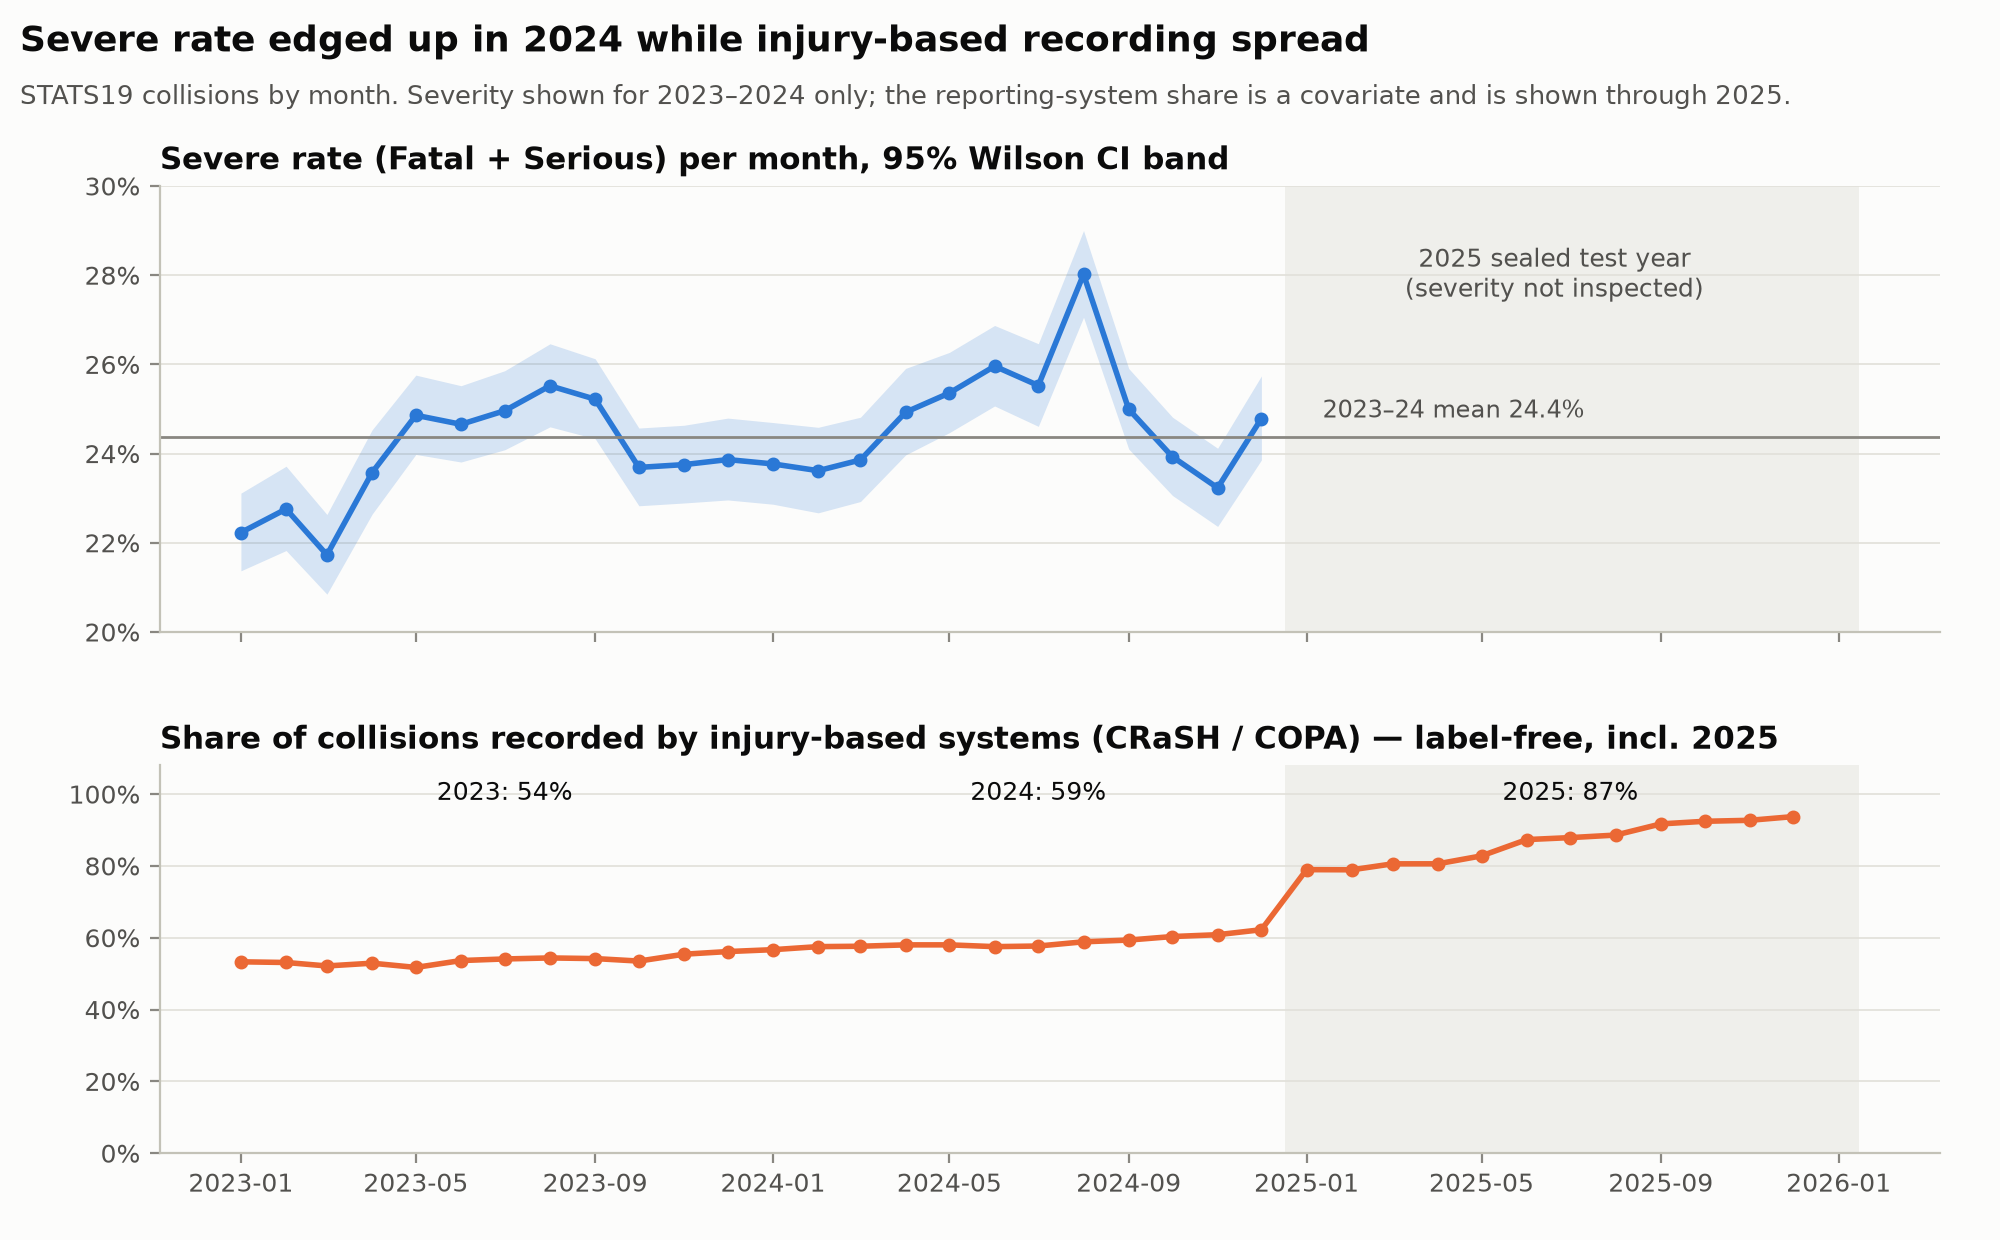

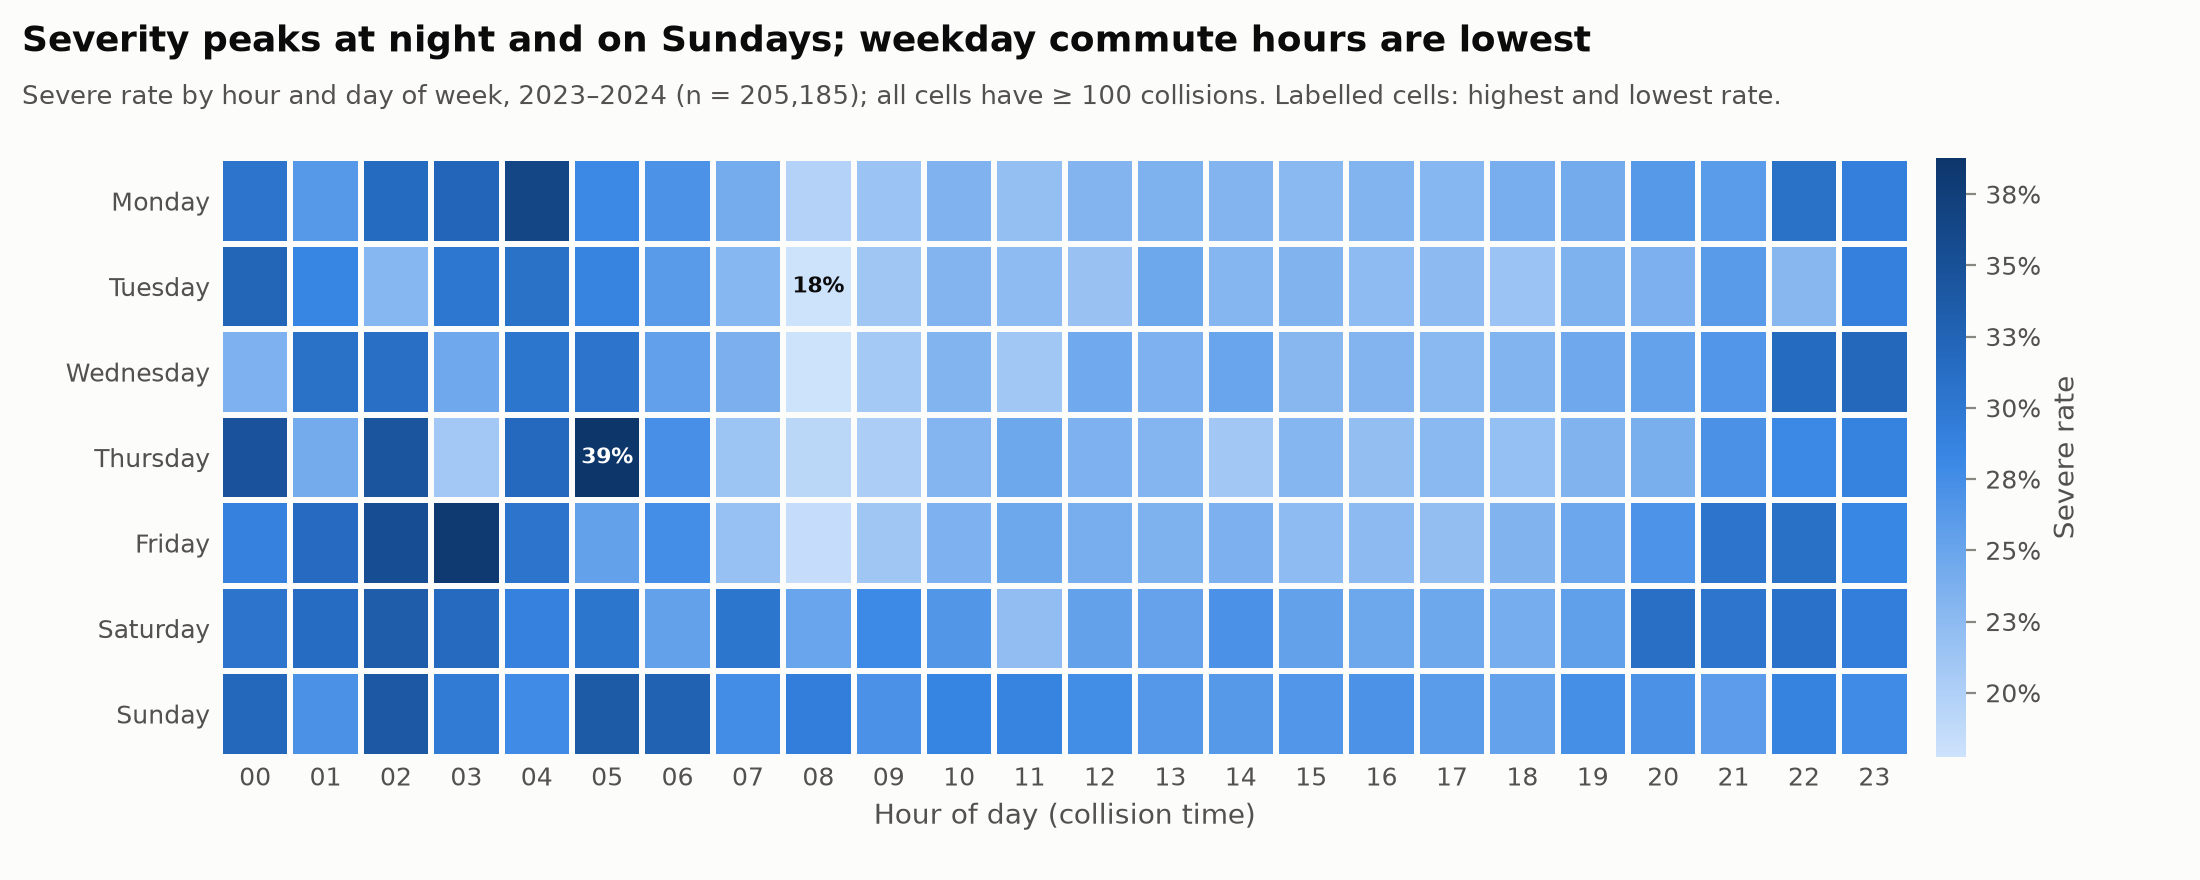

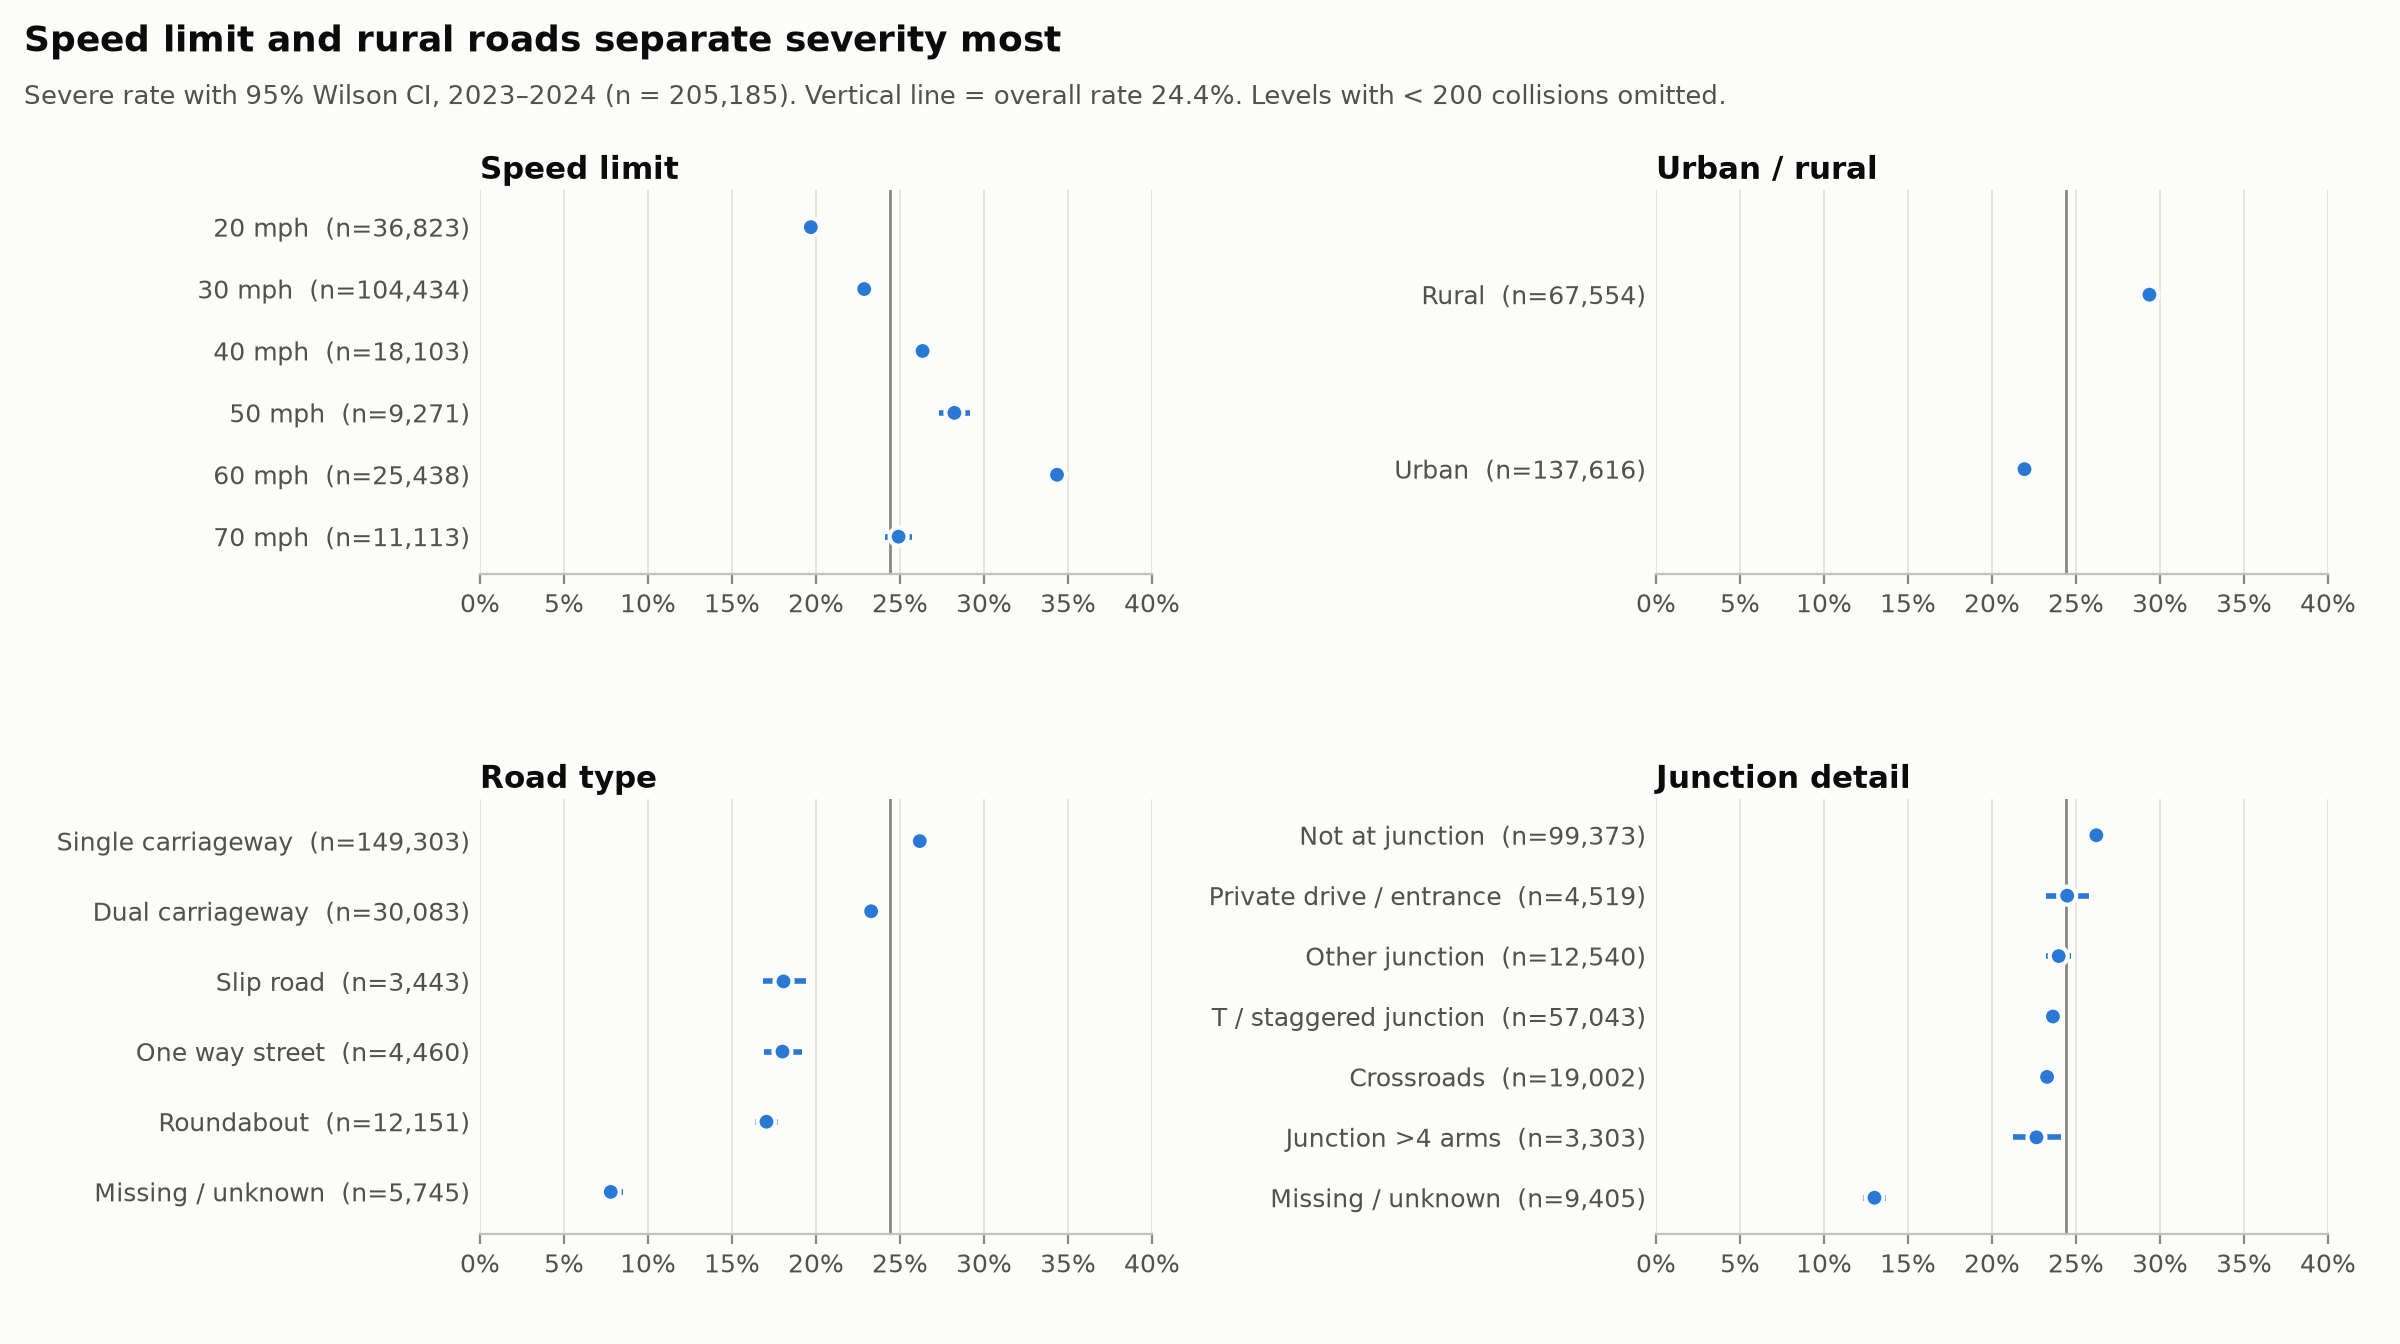

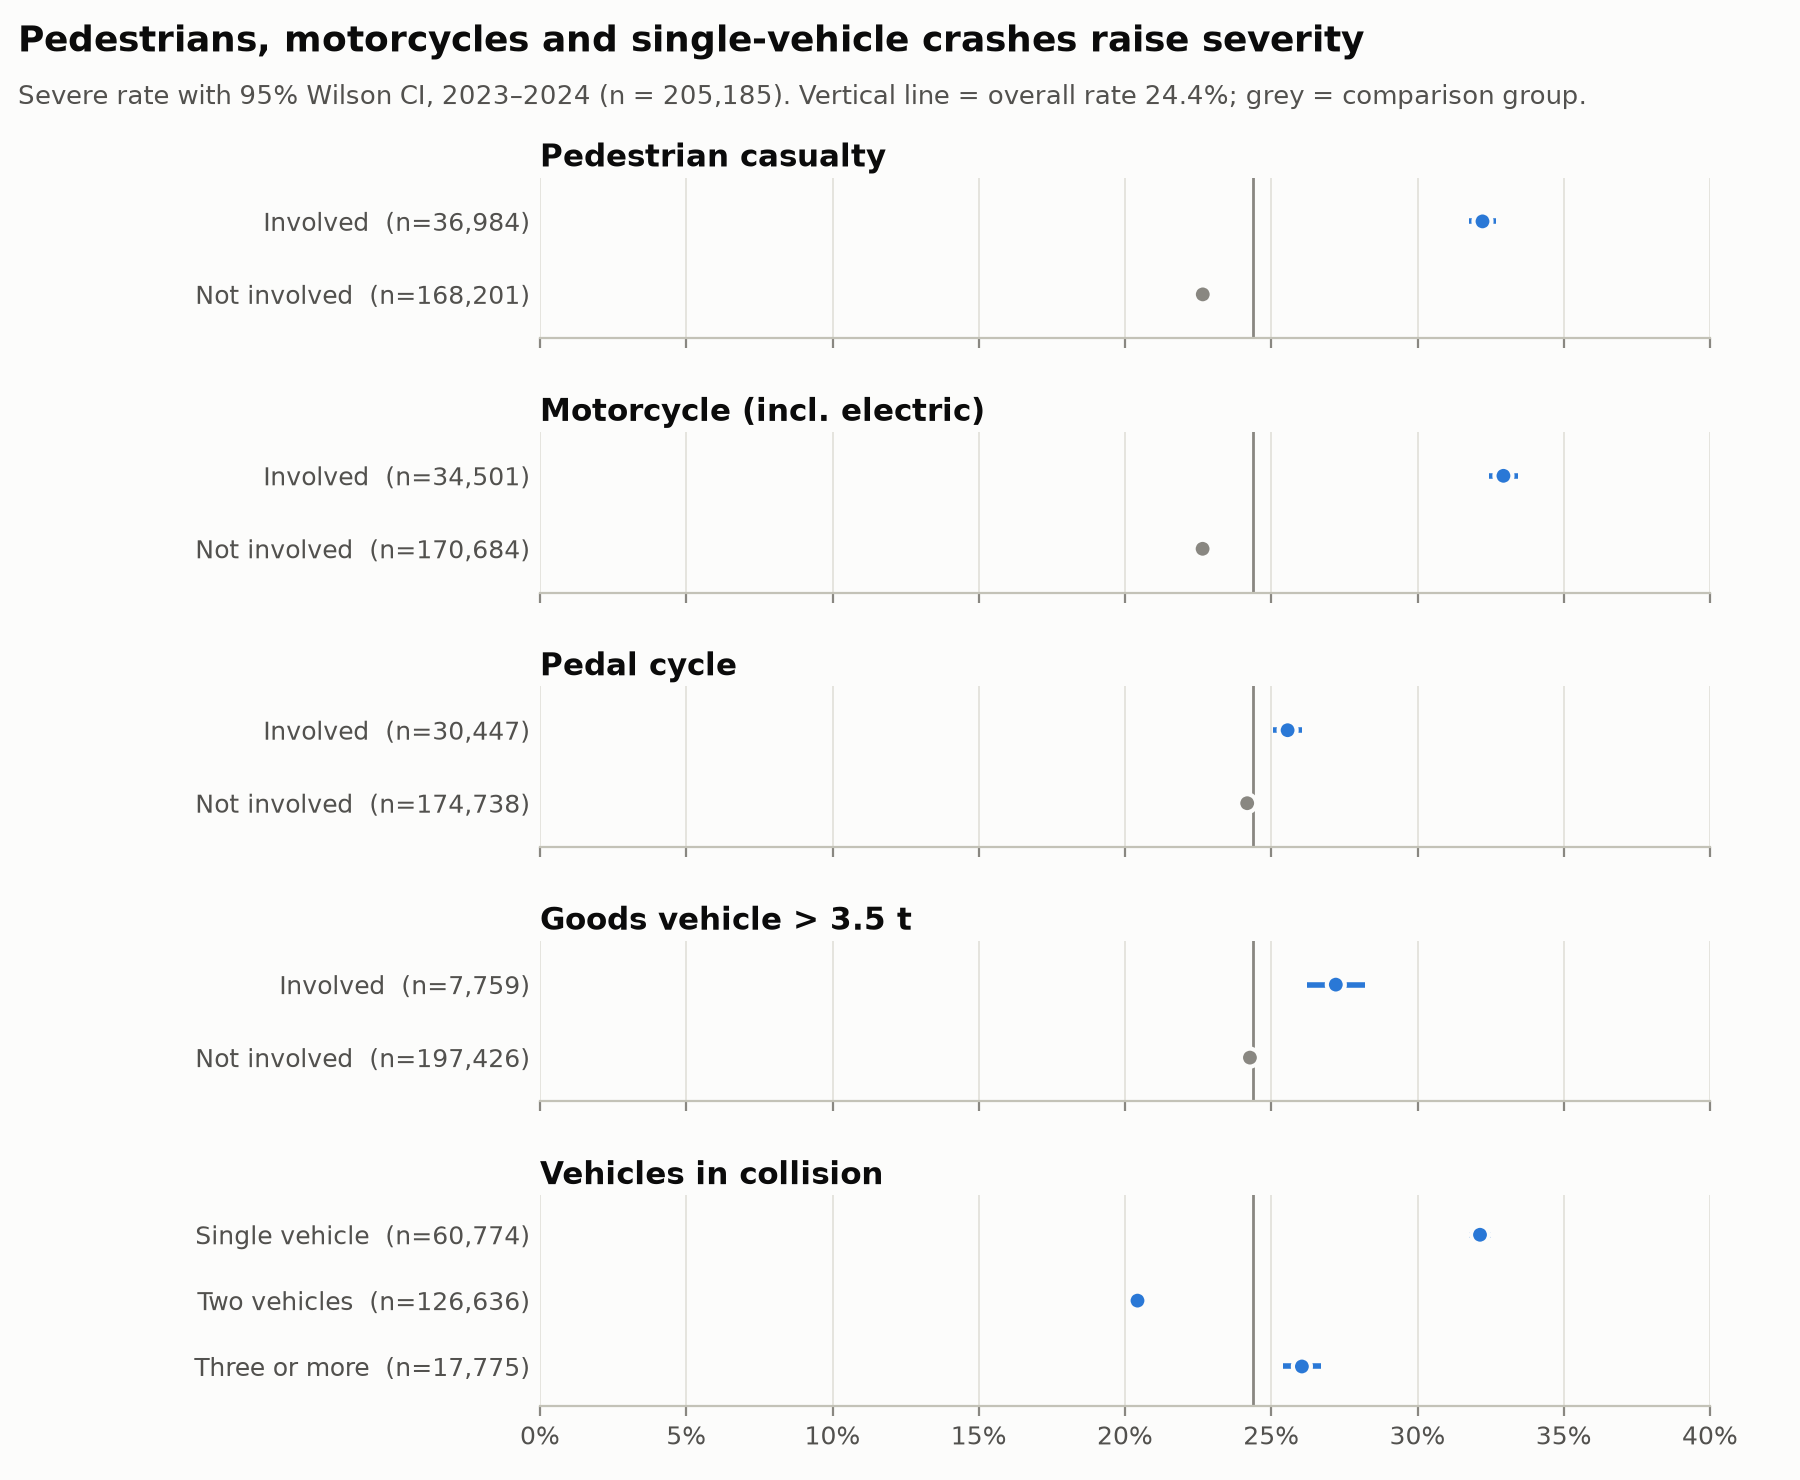

In [4]:
display(Markdown((ROOT / "reports" / "eda_findings.md").read_text()))
for f in ["eda_02_monthly_trend_reporting.png", "eda_03_hour_dow_heatmap.png",
          "eda_04_road_factors.png", "eda_06_vehicle_mix.png"]:
    display(Image(filename=str(F / f), width=850))

## 4. Features and selection

In [5]:
sel = pd.read_csv(T / "feature_selection.csv")
display(sel["selected"].value_counts().rename("count").to_frame())
display(sel[sel["selected"]].sort_values("mean_importance", ascending=False)
        [["feature", "kind", "mean_importance", "n_positive_folds"]].head(20))

,count
selected,
False,127
True,117


,feature,kind,mean_importance,n_positive_folds
187,has_vru,numeric,0.0619,4.0
0,police_force,categorical,0.0265,4.0
166,ped_age,numeric,0.0159,4.0
23,speed_limit,numeric,0.0131,4.0
216,n_age_unknown,numeric,0.0100,4.0
84,veh_vehicle_direction_from__missing,numeric,0.0075,4.0
214,relative_heading,numeric,0.0069,4.0
71,veh_vehicle_manoeuvre__19,numeric,0.0068,4.0
119,veh_vehicle_left_hand_drive__missing,numeric,0.0063,4.0
207,n_motorcycle,numeric,0.0042,4.0


## 5. Pipeline and evaluation design

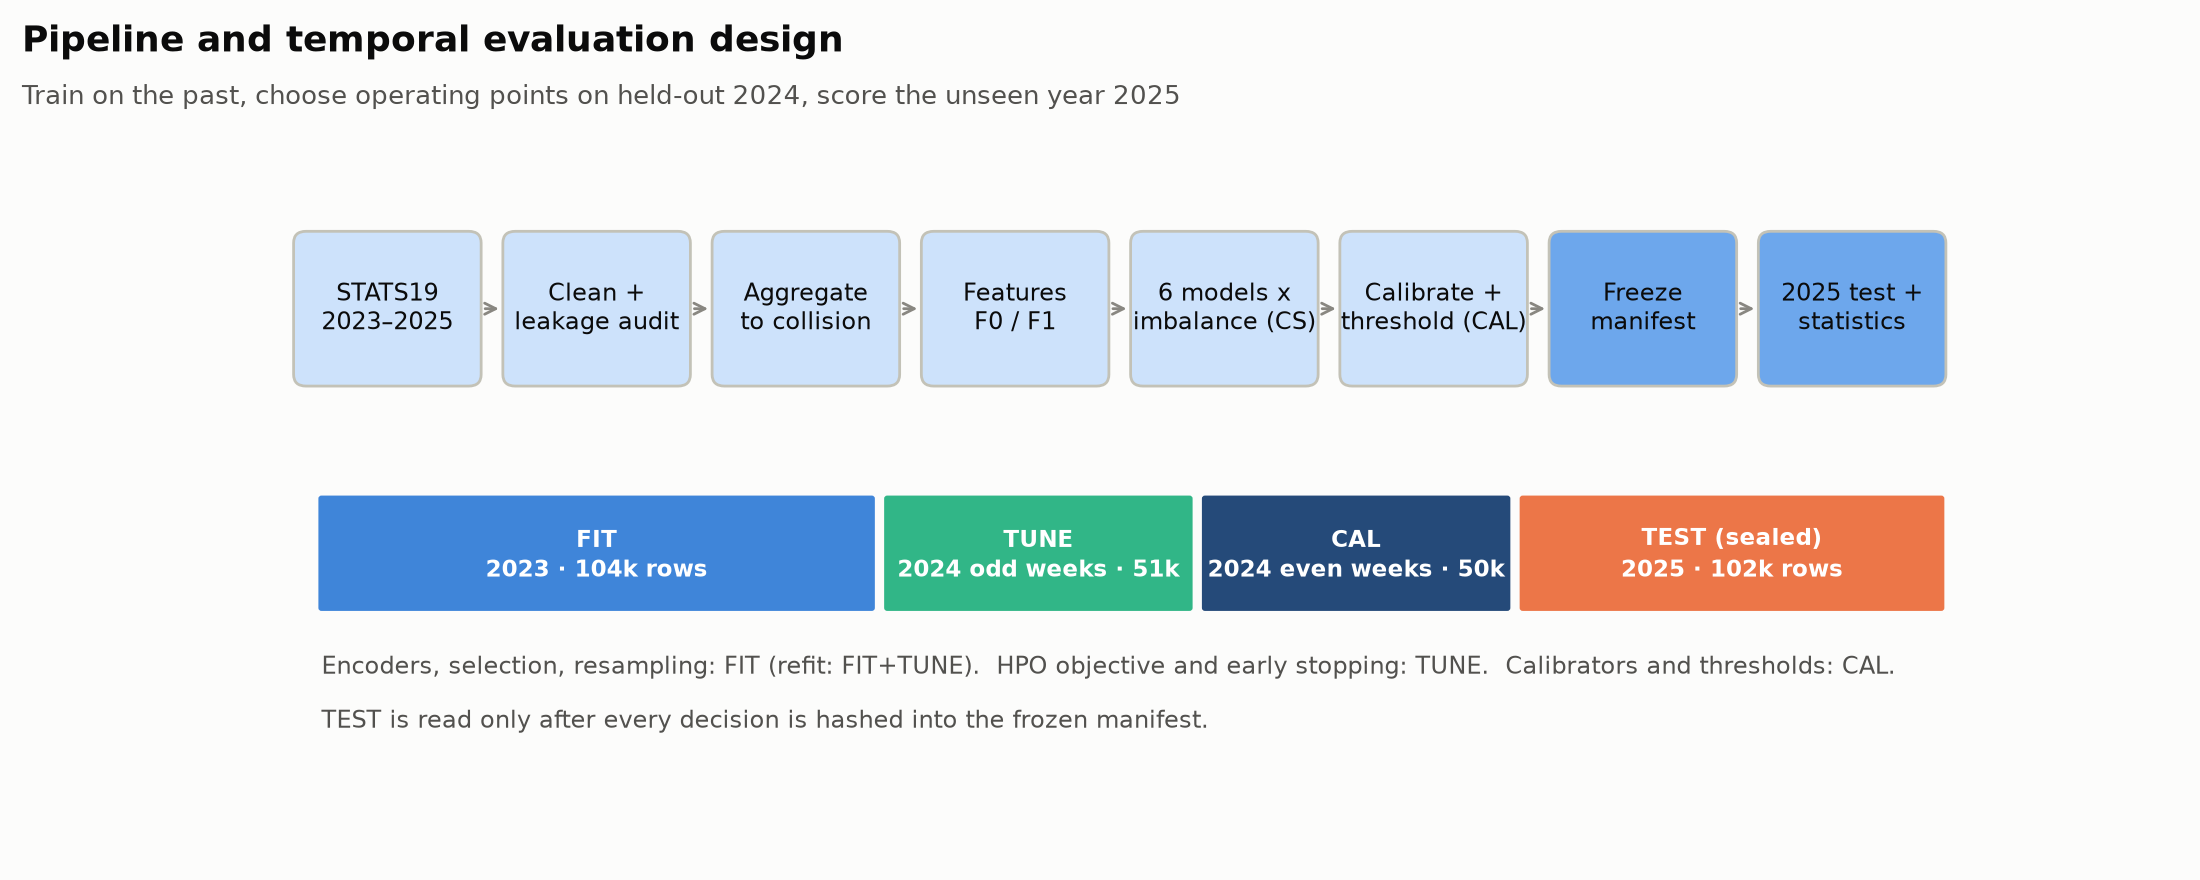

Frozen at: 2026-11-12T00:44:29.535755+00:00
Selected model: {'cell_id': 'F1full__none__lgbm', 'cal_pr_auc': 0.4918370696026864, 'cal_brier_calibrated': 0.16017744466279804, 'tied_cells': ['F1__none__lgbm', 'F1__none__xgb', 'F1__weight__lgbm', 'F1full__none__lgbm']}
CAL-best imbalance strategy per (features, model): {'F0__cat': 'none', 'F0__dt': 'rus', 'F0__lgbm': 'weight', 'F0__lr': 'weight', 'F0__rf': 'weight', 'F0__xgb': 'weight', 'F1__cat': 'weight', 'F1__dt': 'none', 'F1__lgbm': 'none', 'F1__lr': 'rus', 'F1__rf': 'weight', 'F1__xgb': 'none', 'F1full__lgbm': 'none', 'F1full__lr': 'none'}


In [6]:
display(Image(filename=str(F / "fig_01_pipeline.png"), width=950))
manifest = json.loads((ROOT / "experiments" / "frozen_manifest.json").read_text())
print("Frozen at:", manifest["frozen_at"])
print("Selected model:", manifest["selected"])
print("CAL-best imbalance strategy per (features, model):", manifest["best_cs"])

## 6. Results on the unseen 2025 test year
### Best configuration per model family

,model,config,calibrator,pr_auc,roc_auc,brier,ece,recall,precision,f2,expected_cost
0,Logistic Reg.,F1 + Undersampling,platt,0.4735 ± 0.0007,0.7150 ± 0.0002,0.1711 ± 0.0000,0.0101 ± 0.0003,0.9035 ± 0.0058,0.3207 ± 0.0023,0.6626 ± 0.0006,0.6290 ± 0.0010
1,Decision Tree,F1 + None,platt,0.4508 ± 0.0000,0.6999 ± 0.0000,0.1741 ± 0.0000,0.0102 ± 0.0000,0.9364 ± 0.0000,0.3031 ± 0.0000,0.6604 ± 0.0000,0.6485 ± 0.0000
2,Random Forest,F1 + Class weight,platt,0.4837 ± 0.0005,0.7239 ± 0.0002,0.1692 ± 0.0001,0.0089 ± 0.0001,0.9180 ± 0.0143,0.3181 ± 0.0059,0.6664 ± 0.0008,0.6244 ± 0.0038
3,XGBoost,F1 + None,platt,0.4966 ± 0.0003,0.7310 ± 0.0003,0.1674 ± 0.0000,0.0087 ± 0.0002,0.9112 ± 0.0072,0.3234 ± 0.0030,0.6683 ± 0.0006,0.6168 ± 0.0015
4,LightGBM,F1 + None,platt,0.4962 ± 0.0003,0.7307 ± 0.0002,0.1675 ± 0.0000,0.0096 ± 0.0002,0.9033 ± 0.0160,0.3275 ± 0.0068,0.6681 ± 0.0014,0.6142 ± 0.0024
5,CatBoost,F1 + Class weight,platt,0.4928 ± 0.0002,0.7284 ± 0.0001,0.1680 ± 0.0000,0.0088 ± 0.0008,0.9173 ± 0.0043,0.3193 ± 0.0020,0.6673 ± 0.0002,0.6217 ± 0.0016


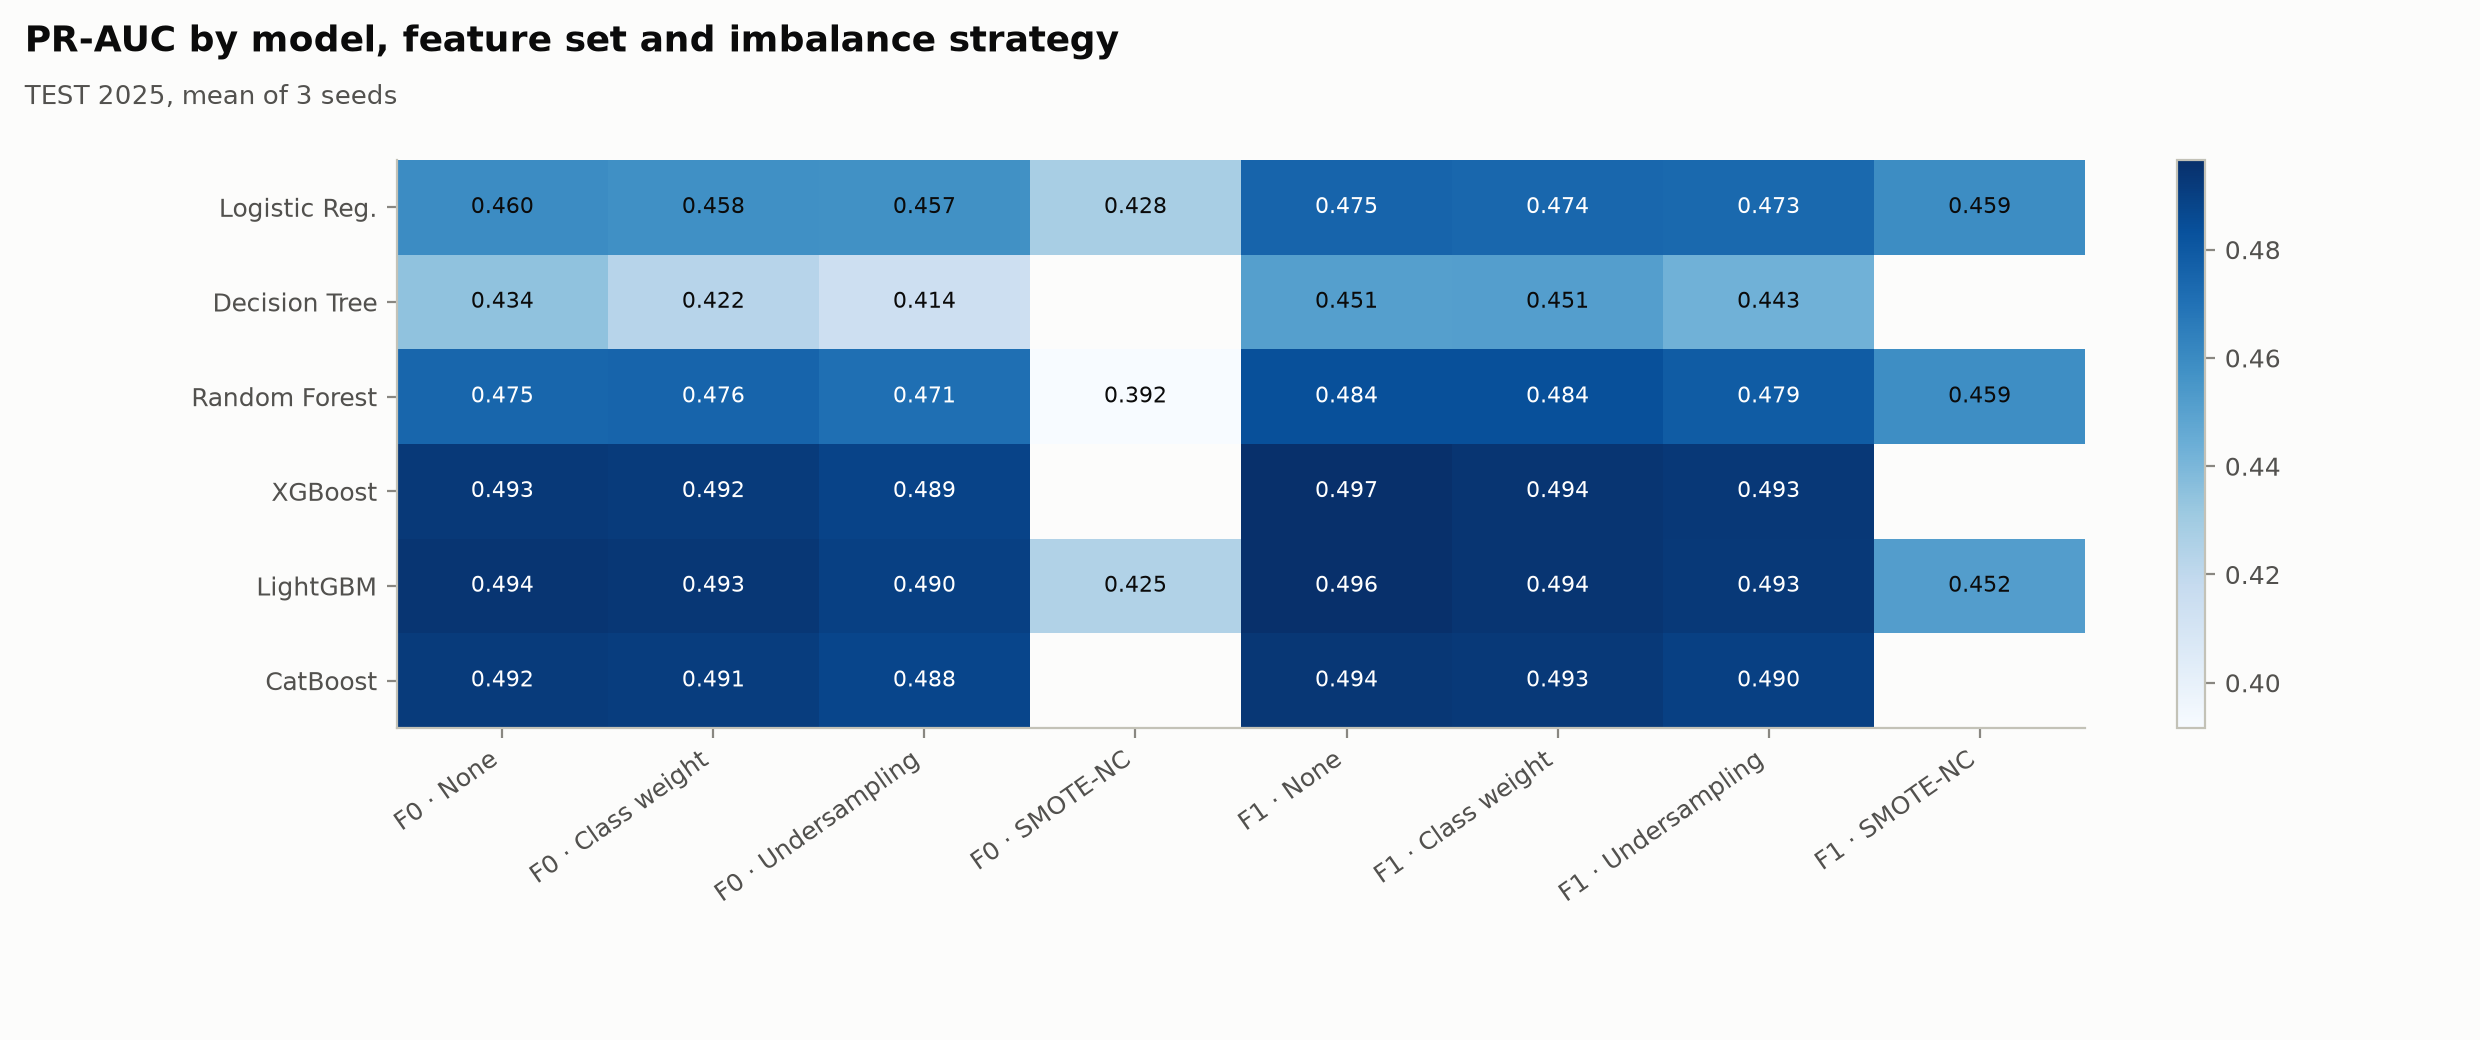

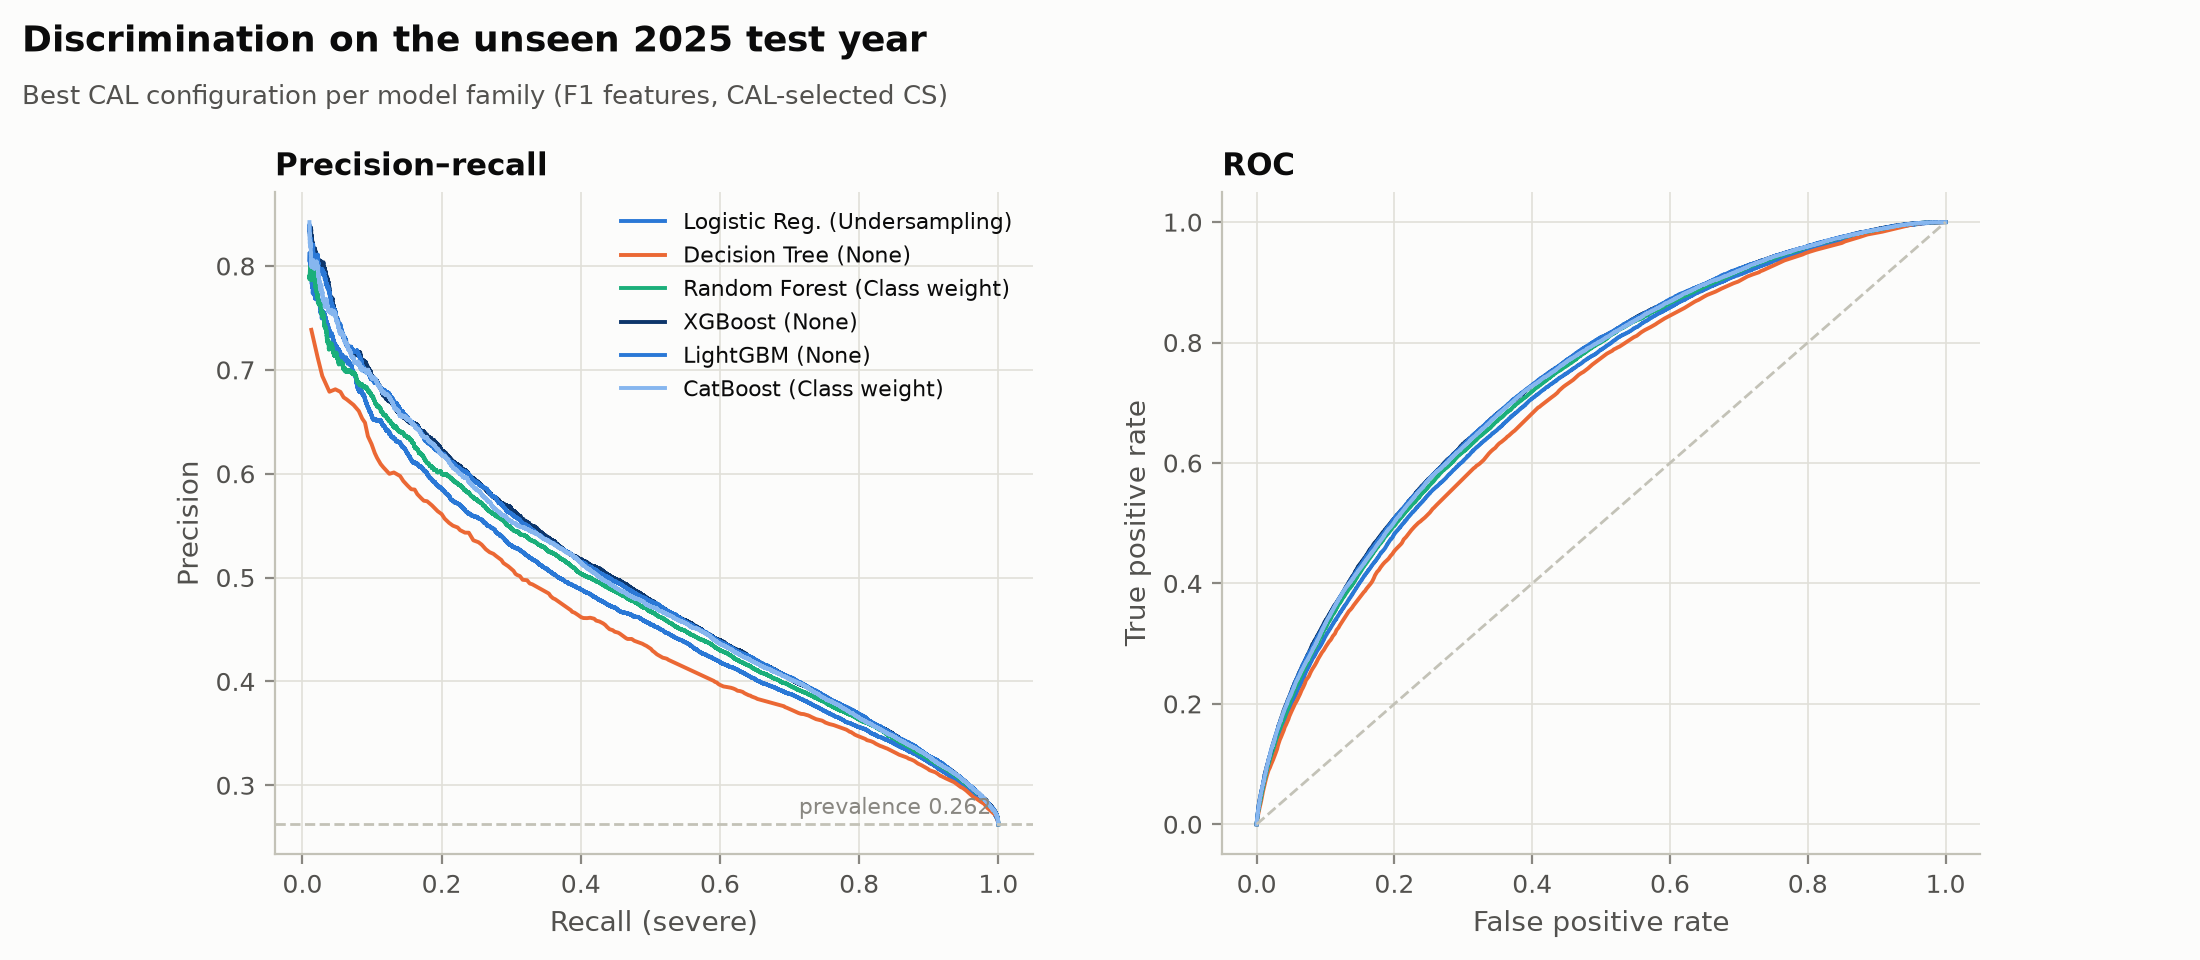

In [7]:
display(pd.read_csv(T / "main_results.csv"))
display(Image(filename=str(F / "fig_02_ablation_prauc.png"), width=900))
display(Image(filename=str(F / "fig_14_pr_roc.png"), width=950))

### Research questions — prespecified primary contrasts (Holm-adjusted)

,rq,model,contrast,primary_metric,p_primary,p_holm,delta,ci
0,RQ1,cat,"F1 vs F0 (no CS, raw)",pr_auc,0.0280,0.2239,0.0019,"[+0.0003, +0.0036]"
1,RQ2,cat,"weight vs none (F0, raw)",f2@op,0.3168,1.0000,0.0006,"[-0.0006, +0.0019]"
2,RQ3,cat,"best calibrator vs raw (F1, weight)",brier,0.0010,0.0180,-0.0412,"[-0.0418, -0.0407]"
3,ALL,cat,F1+weight+calibrated@tf2 vs F0+none+raw@0.5,f2@op,0.0010,0.0060,0.4208,"[+0.4154, +0.4265]"
4,RQ1,dt,"F1 vs F0 (no CS, raw)",pr_auc,0.0010,0.0180,0.0165,"[+0.0125, +0.0206]"
5,RQ2,dt,"weight vs none (F0, raw)",f2@op,0.9075,1.0000,-0.0002,"[-0.0021, +0.0020]"
6,RQ3,dt,"best calibrator vs raw (F1, none)",brier,0.0010,0.0180,-0.0004,"[-0.0004, -0.0003]"
7,ALL,dt,F1+none+calibrated@tf2 vs F0+none+raw@0.5,f2@op,0.0010,0.0060,0.4532,"[+0.4480, +0.4585]"
8,RQ1,lgbm,"F1 vs F0 (no CS, raw)",pr_auc,0.0790,0.5527,0.0014,"[-0.0001, +0.0029]"
9,RQ2,lgbm,"weight vs none (F0, raw)",f2@op,0.6327,1.0000,-0.0003,"[-0.0014, +0.0008]"


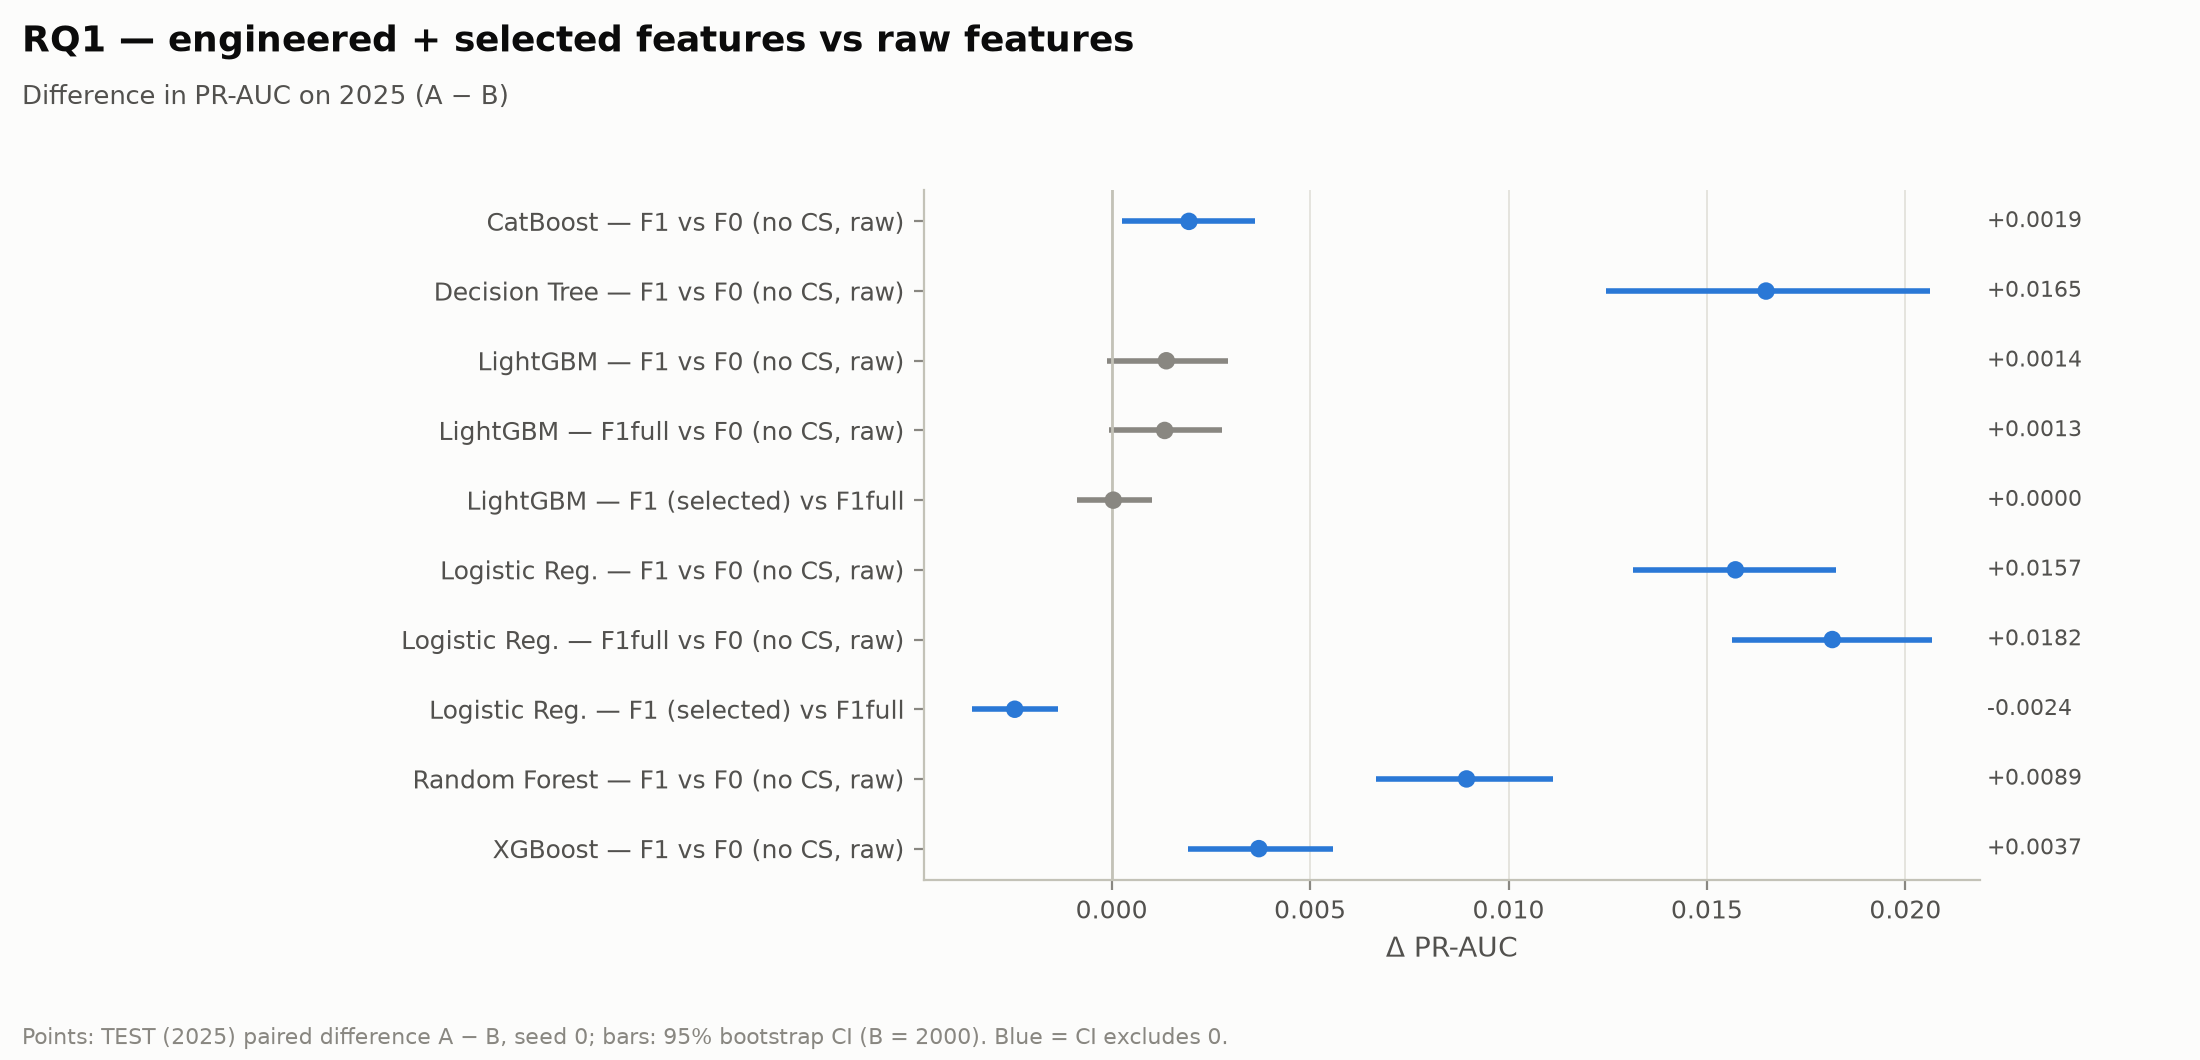

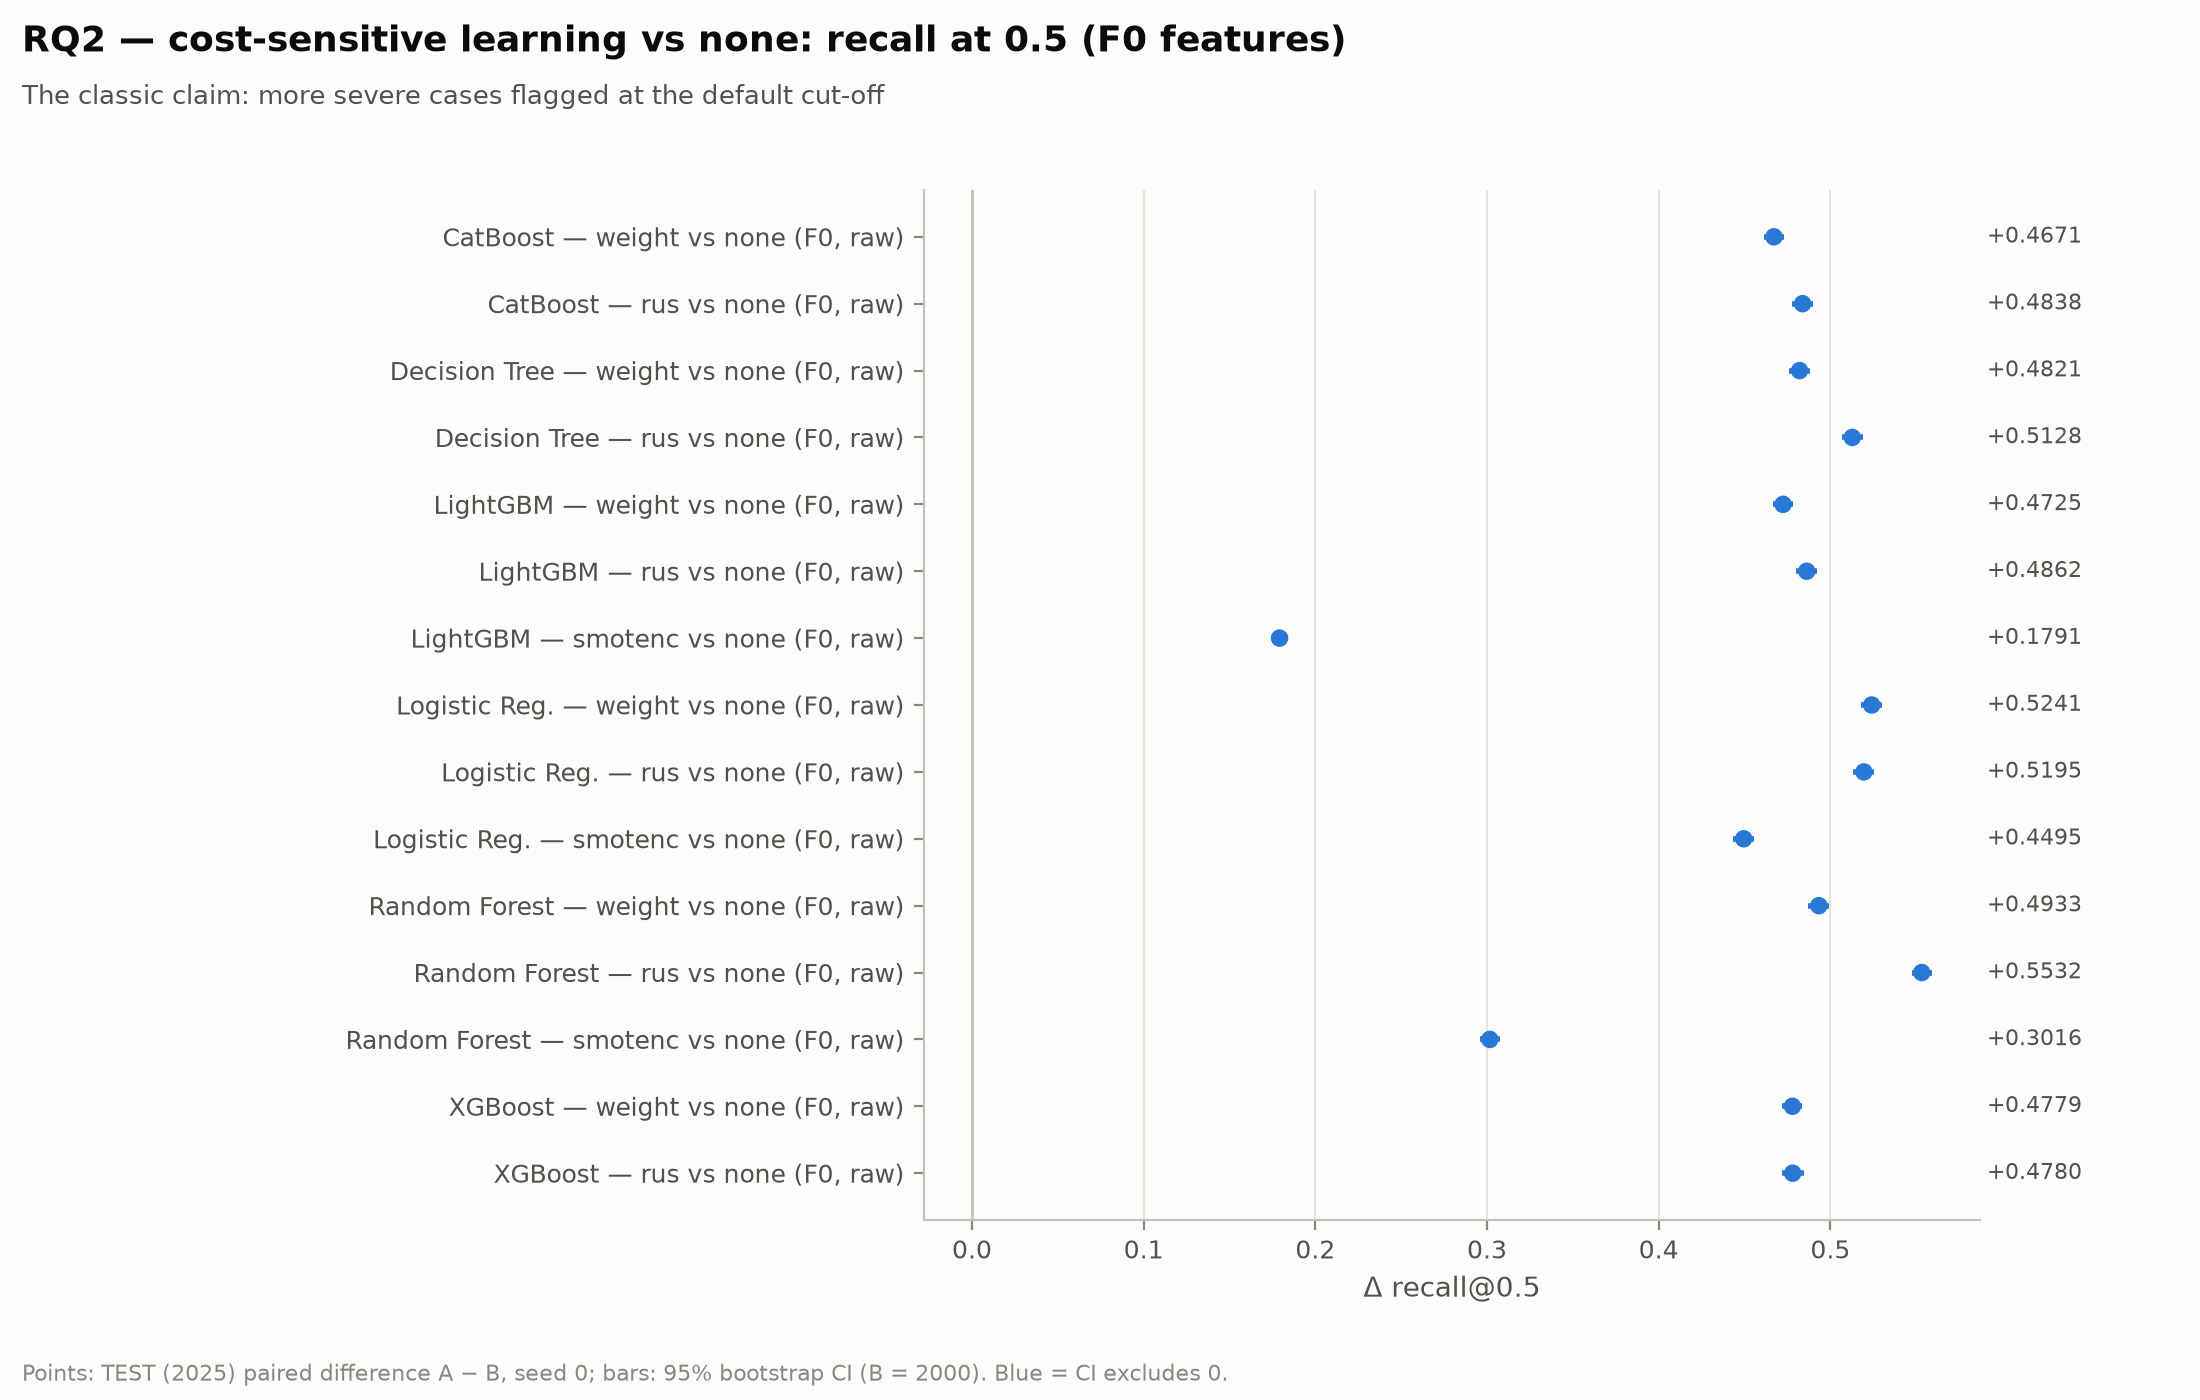

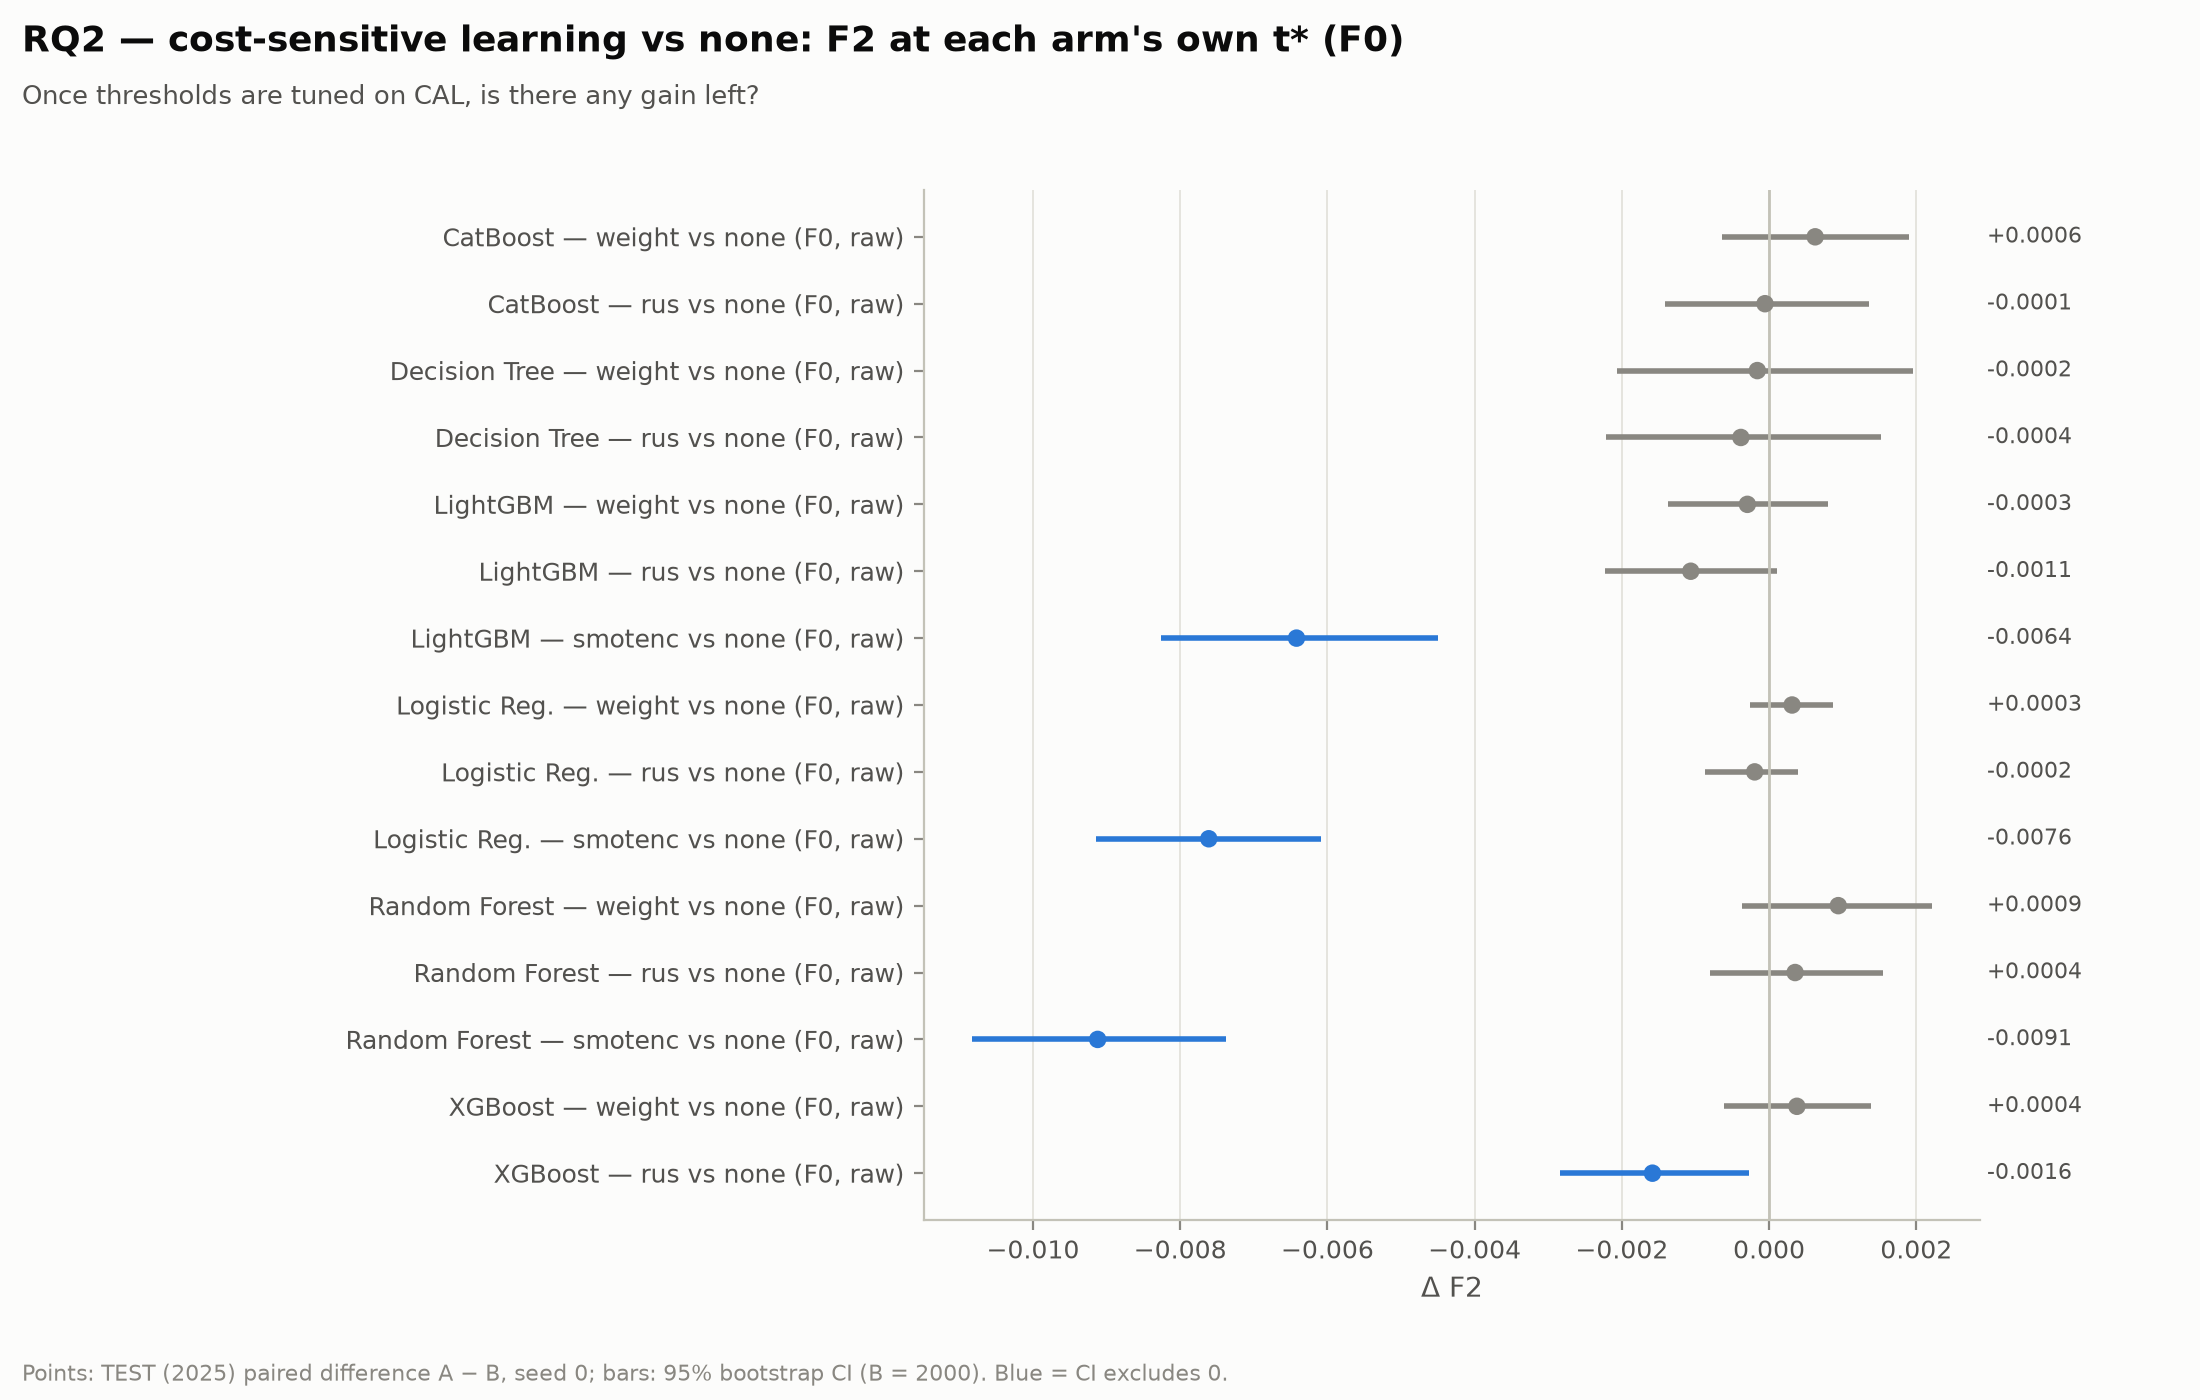

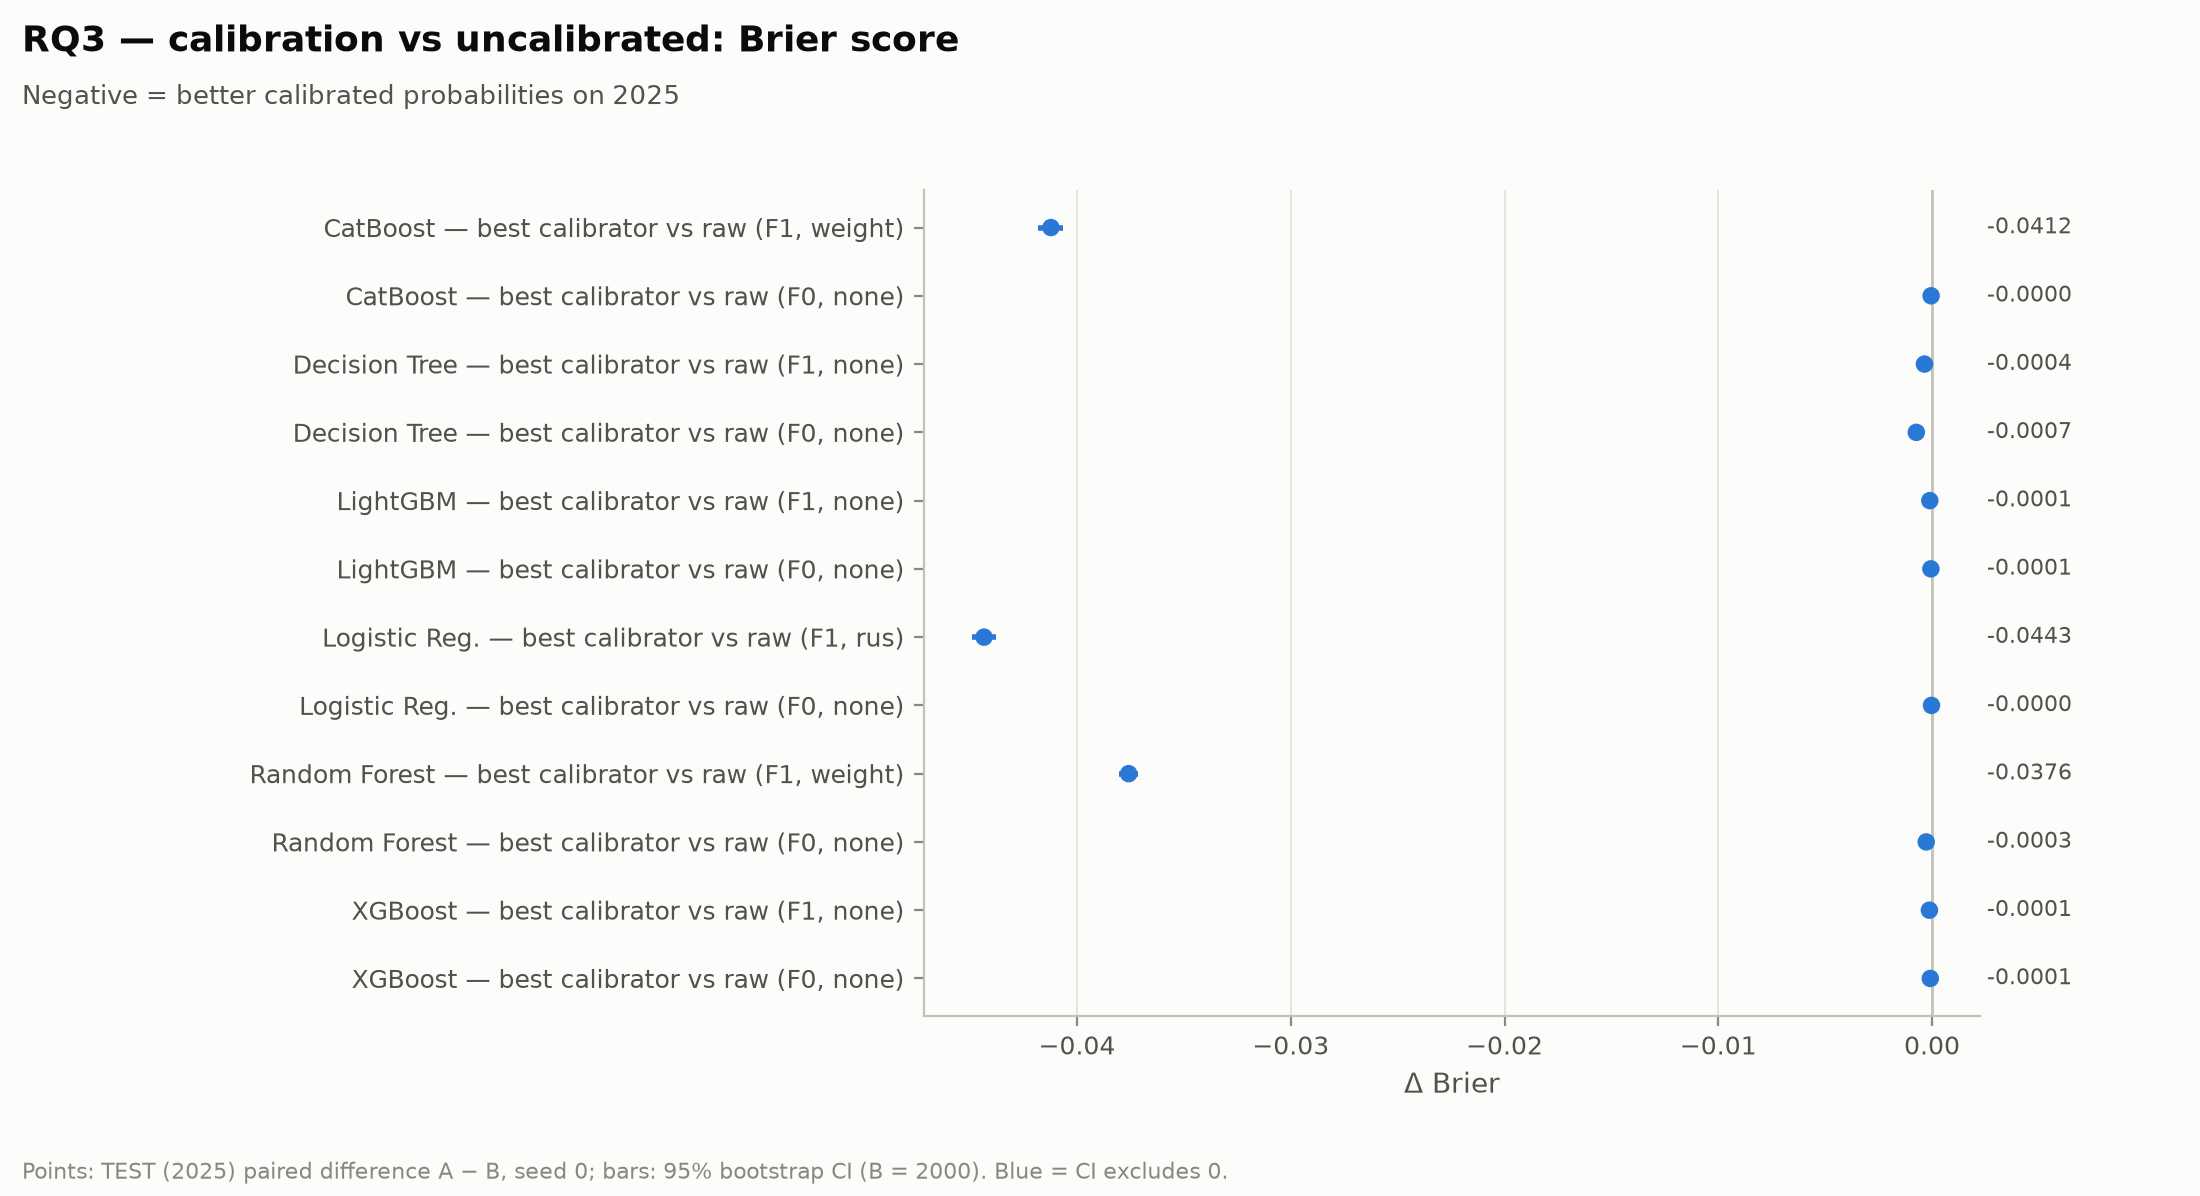

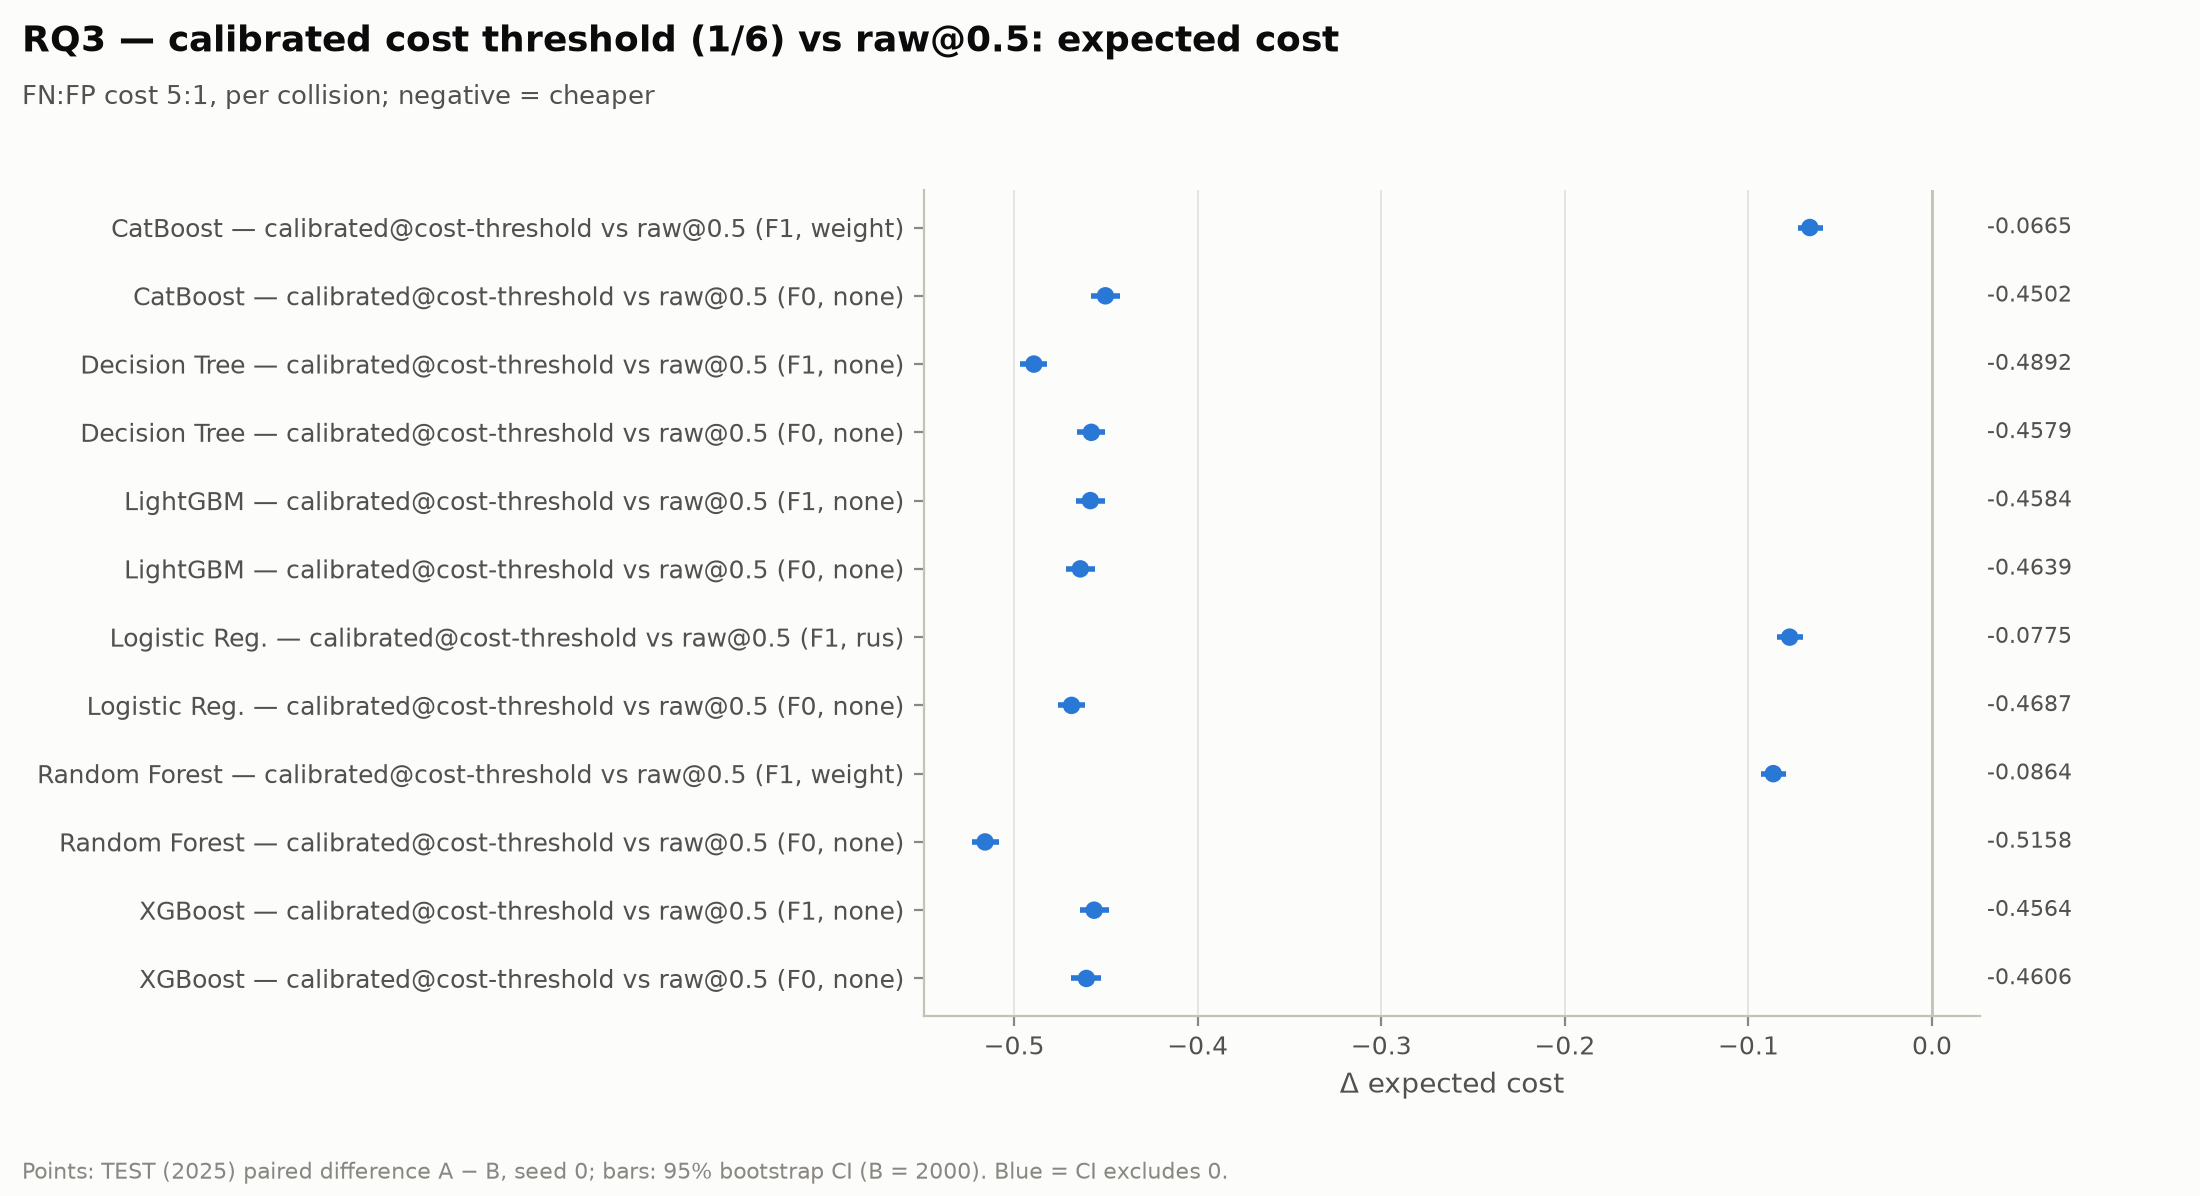

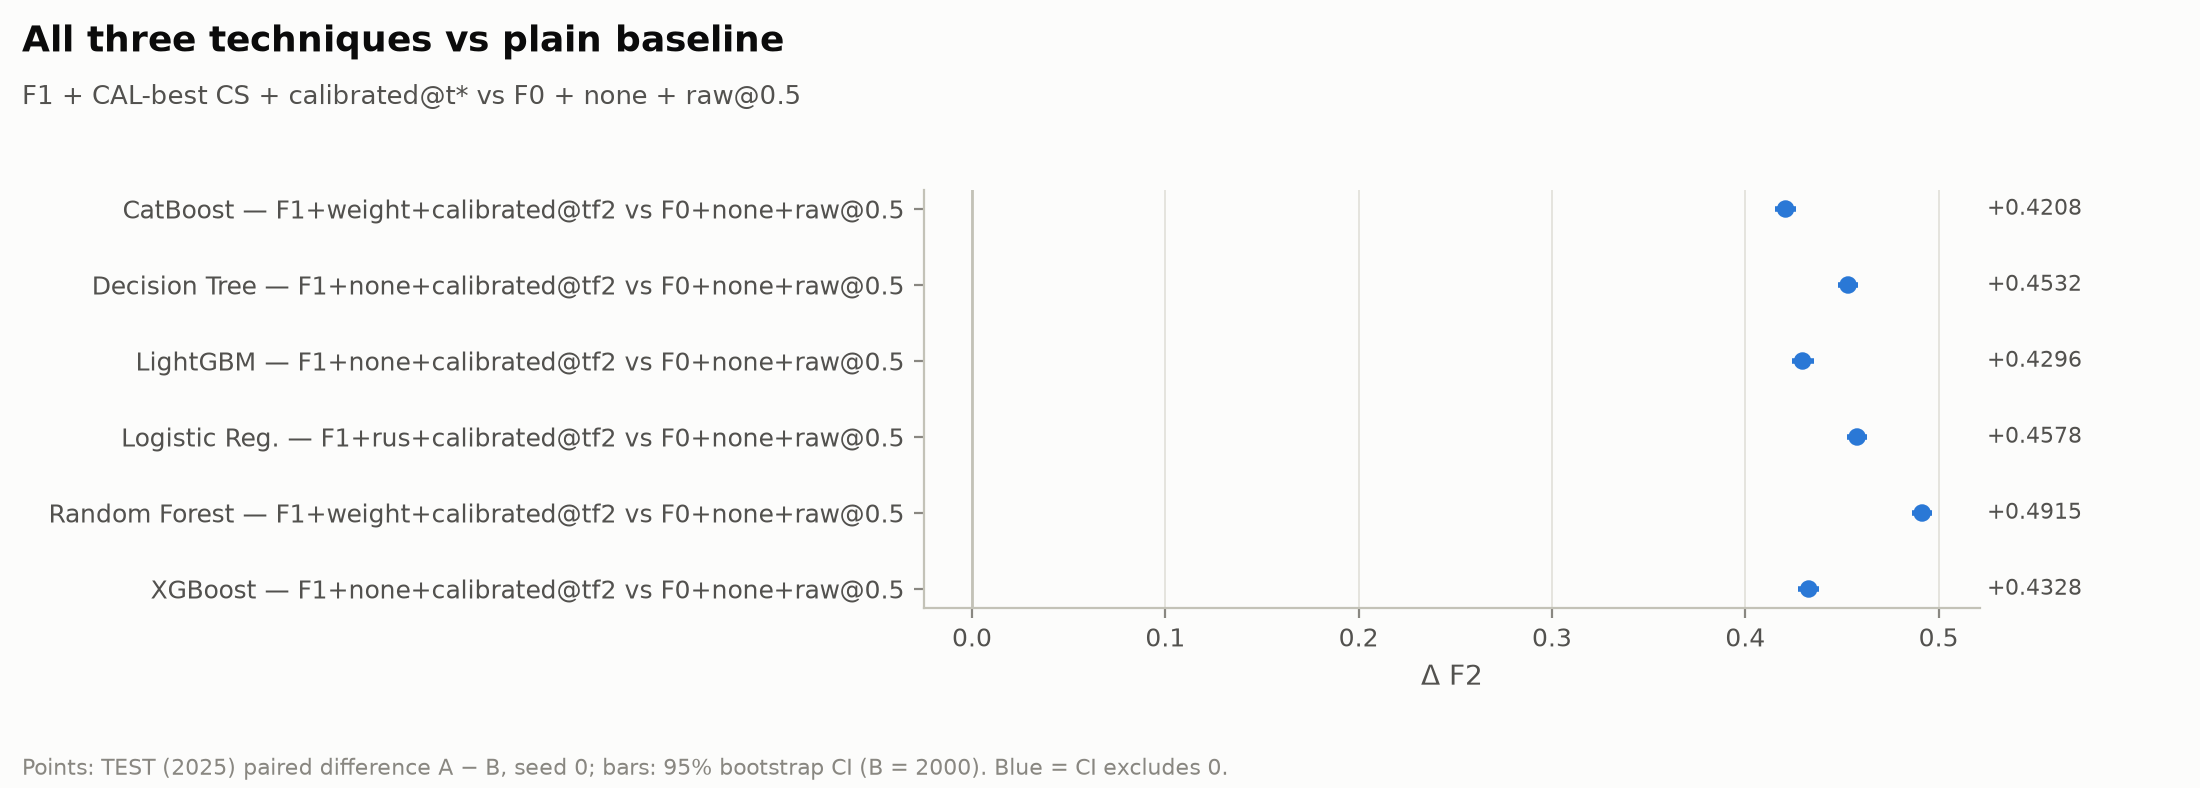

In [8]:
display(pd.read_csv(T / "rq_contrasts_primary.csv"))
for f in ["fig_04_rq1_prauc.png", "fig_05_rq2_recall05.png", "fig_06_rq2_f2.png",
          "fig_07_rq3_brier.png", "fig_08_rq3_cost.png", "fig_09_combined_f2.png"]:
    if (F / f).exists():
        display(Image(filename=str(F / f), width=900))

### Calibration, thresholds and errors of the selected model

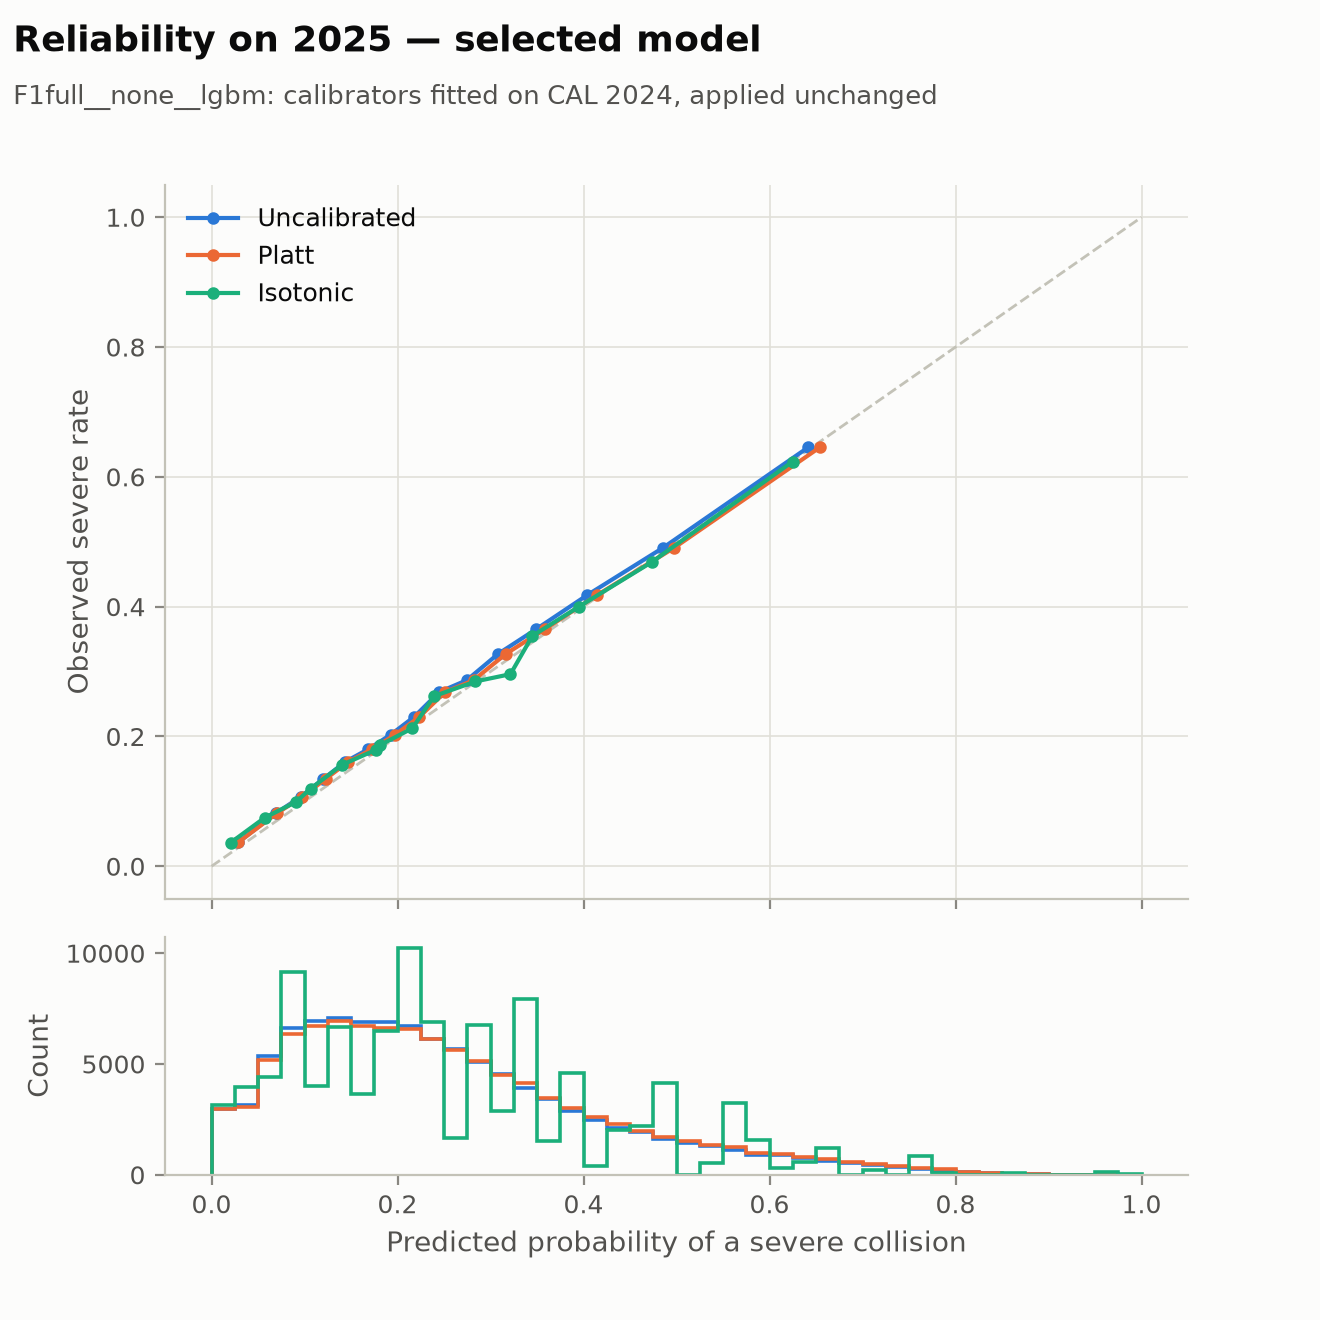

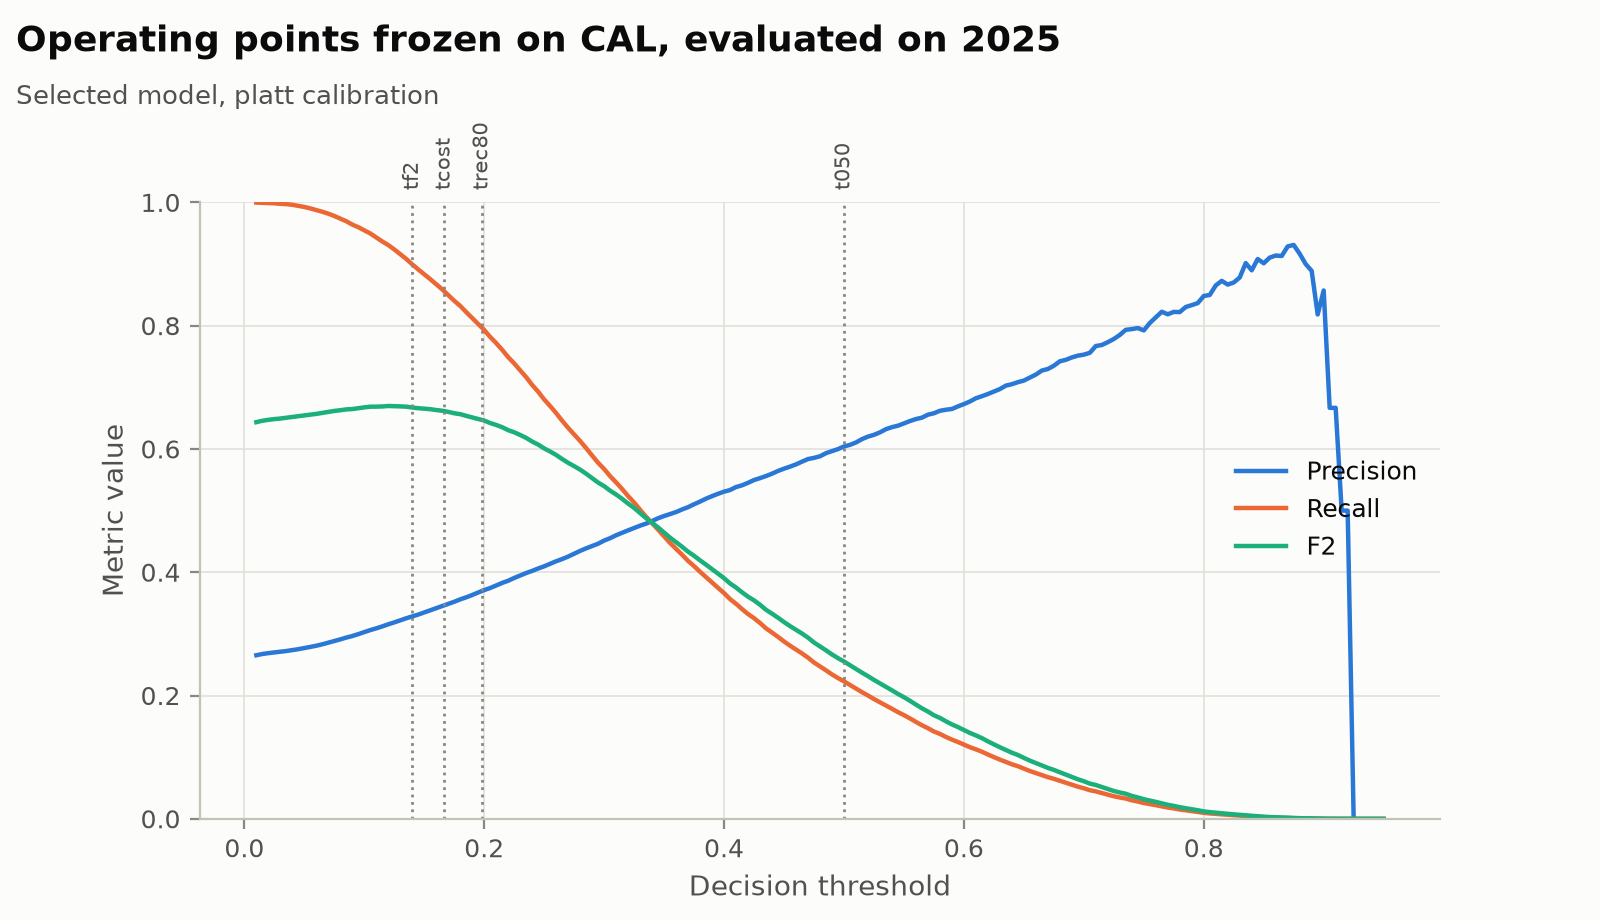

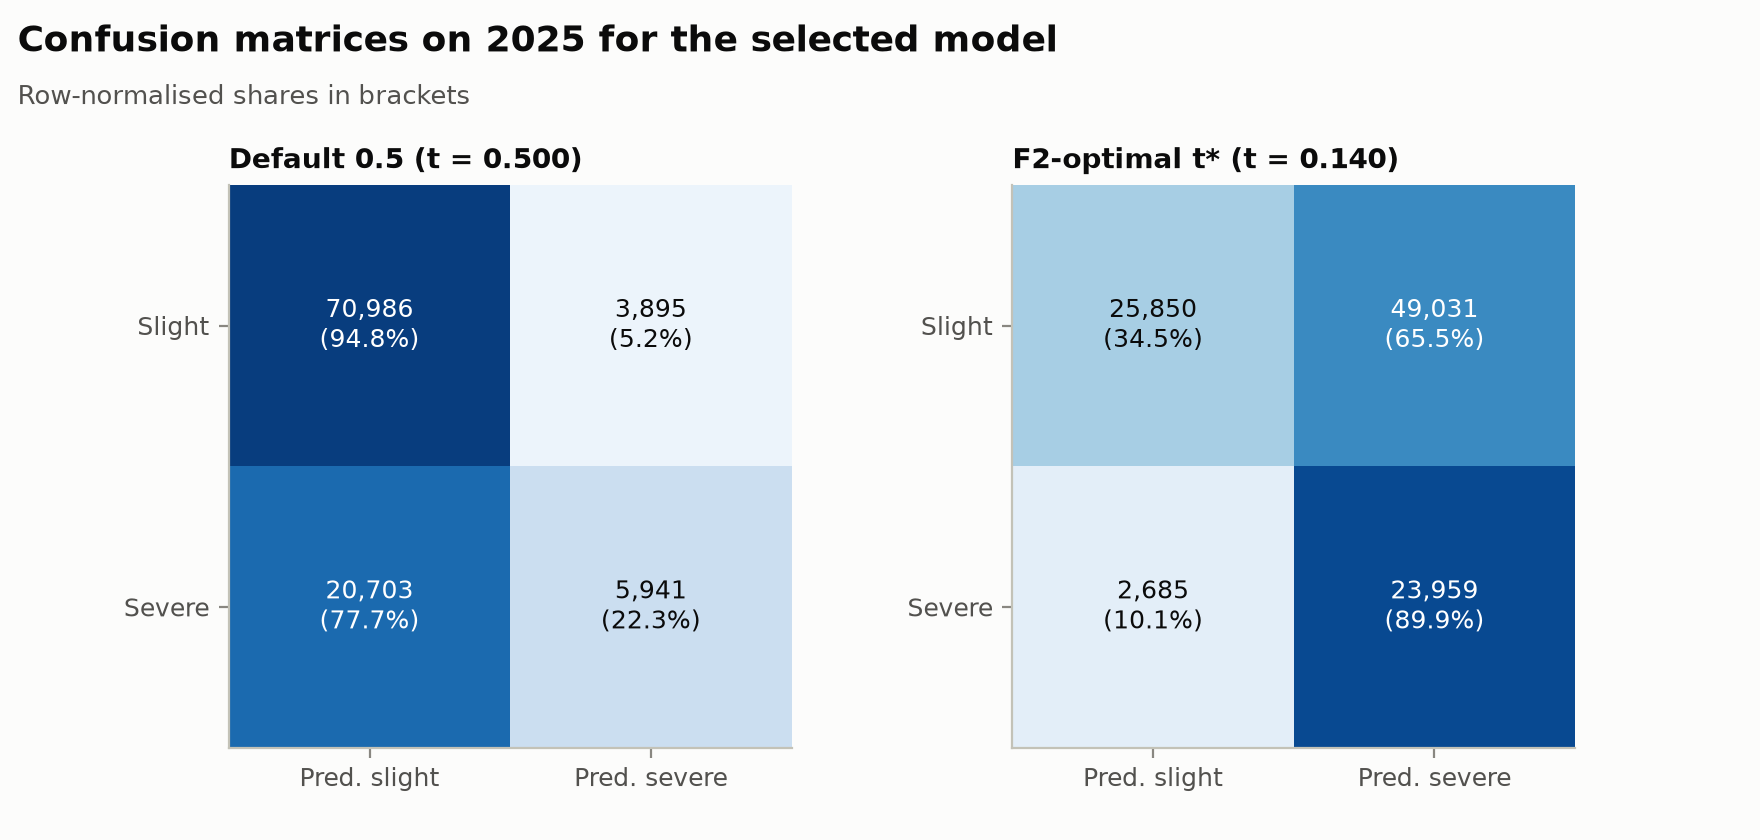

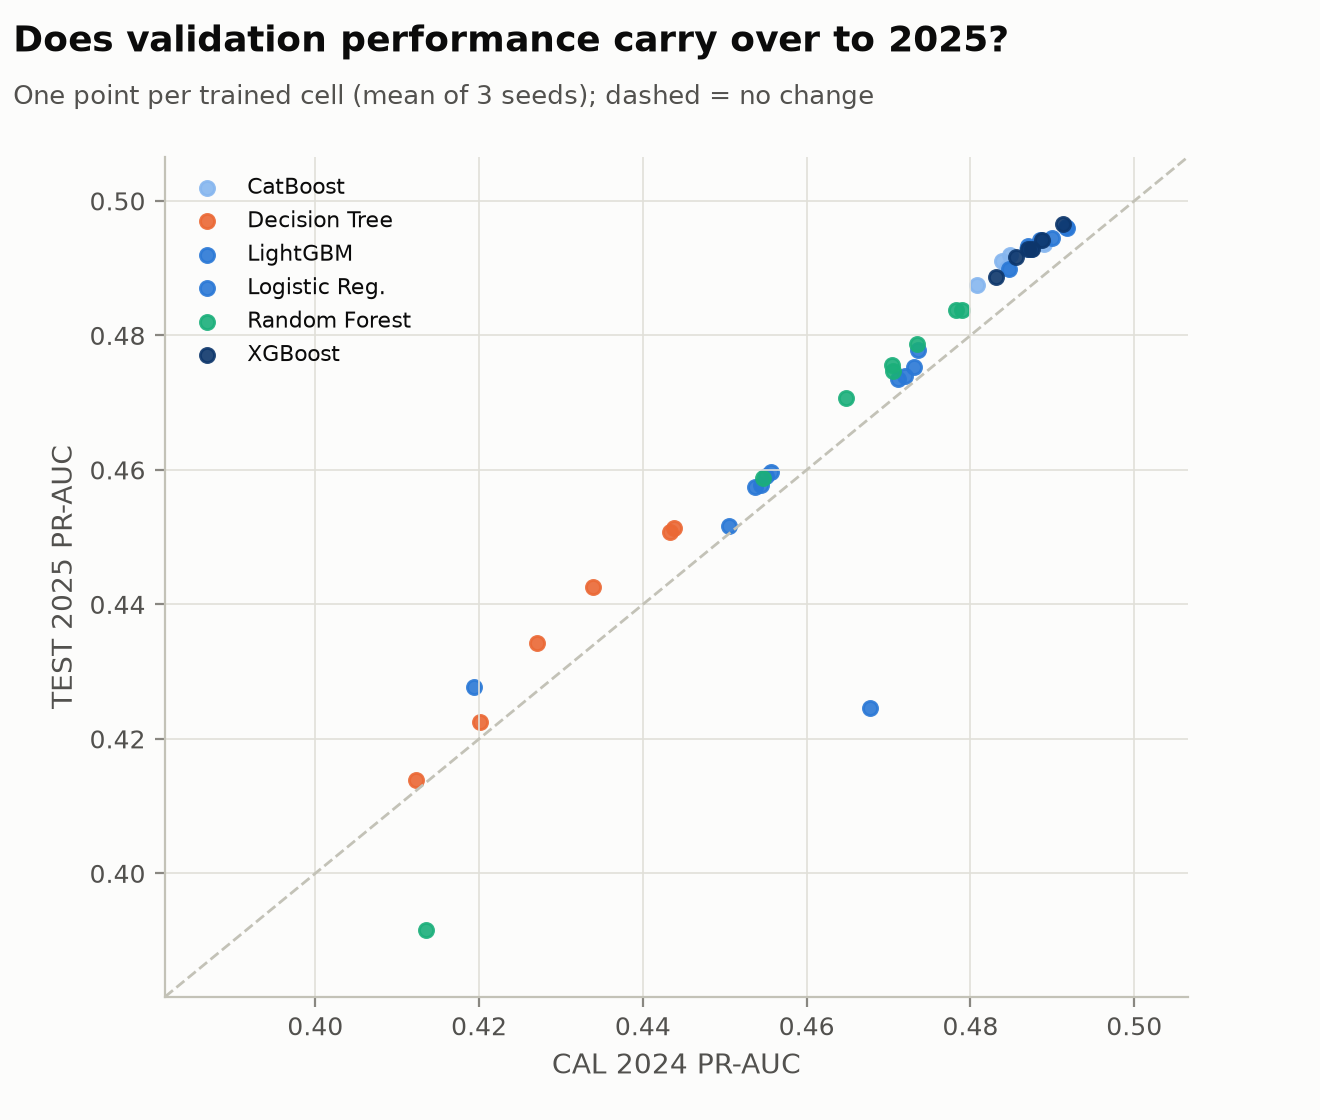

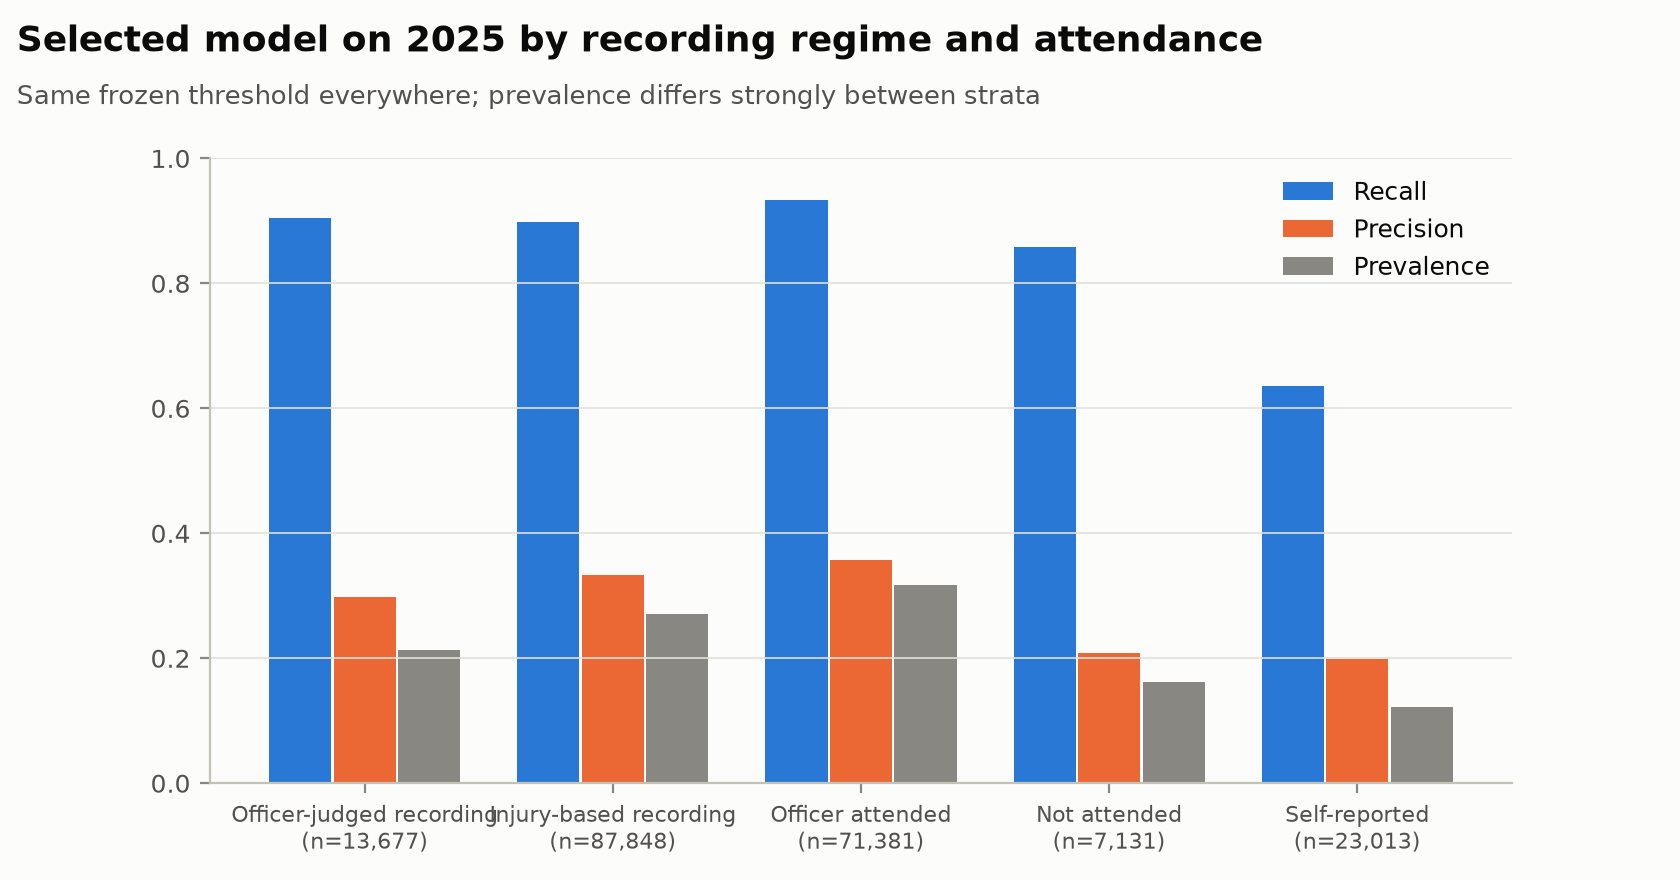

In [9]:
for f in ["fig_11_reliability_selected.png", "fig_12_threshold_curves.png",
          "fig_13_confusion.png", "fig_15_val_test_prauc.png", "fig_16_stratified.png"]:
    if (F / f).exists():
        display(Image(filename=str(F / f), width=800))

## 7. Explainability (SHAP) and sensitivity analyses

,Unnamed: 0,mean_abs_shap_cal,mean_abs_shap_test,rank_test
0,has_vru,0.2101,0.2102,1
1,police_force,0.1240,0.1217,2
2,n_age_unknown,0.1108,0.1109,3
3,speed_limit,0.0990,0.0993,4
4,min_mass_class,0.0910,0.0922,5
5,te_ons_district,0.0891,0.0859,6
6,relative_heading,0.0862,0.0844,7
7,veh_vehicle_manoeuvre__19,0.0819,0.0827,8
8,veh_driver_imd_decile__missing,0.0761,0.0770,9
9,veh_vehicle_left_hand_drive__missing,0.0774,0.0691,10


{'cell_id': 'F1full__none__lgbm', 'spearman_cal_vs_test': 0.9995146333497327, 'n_sample': 20000}


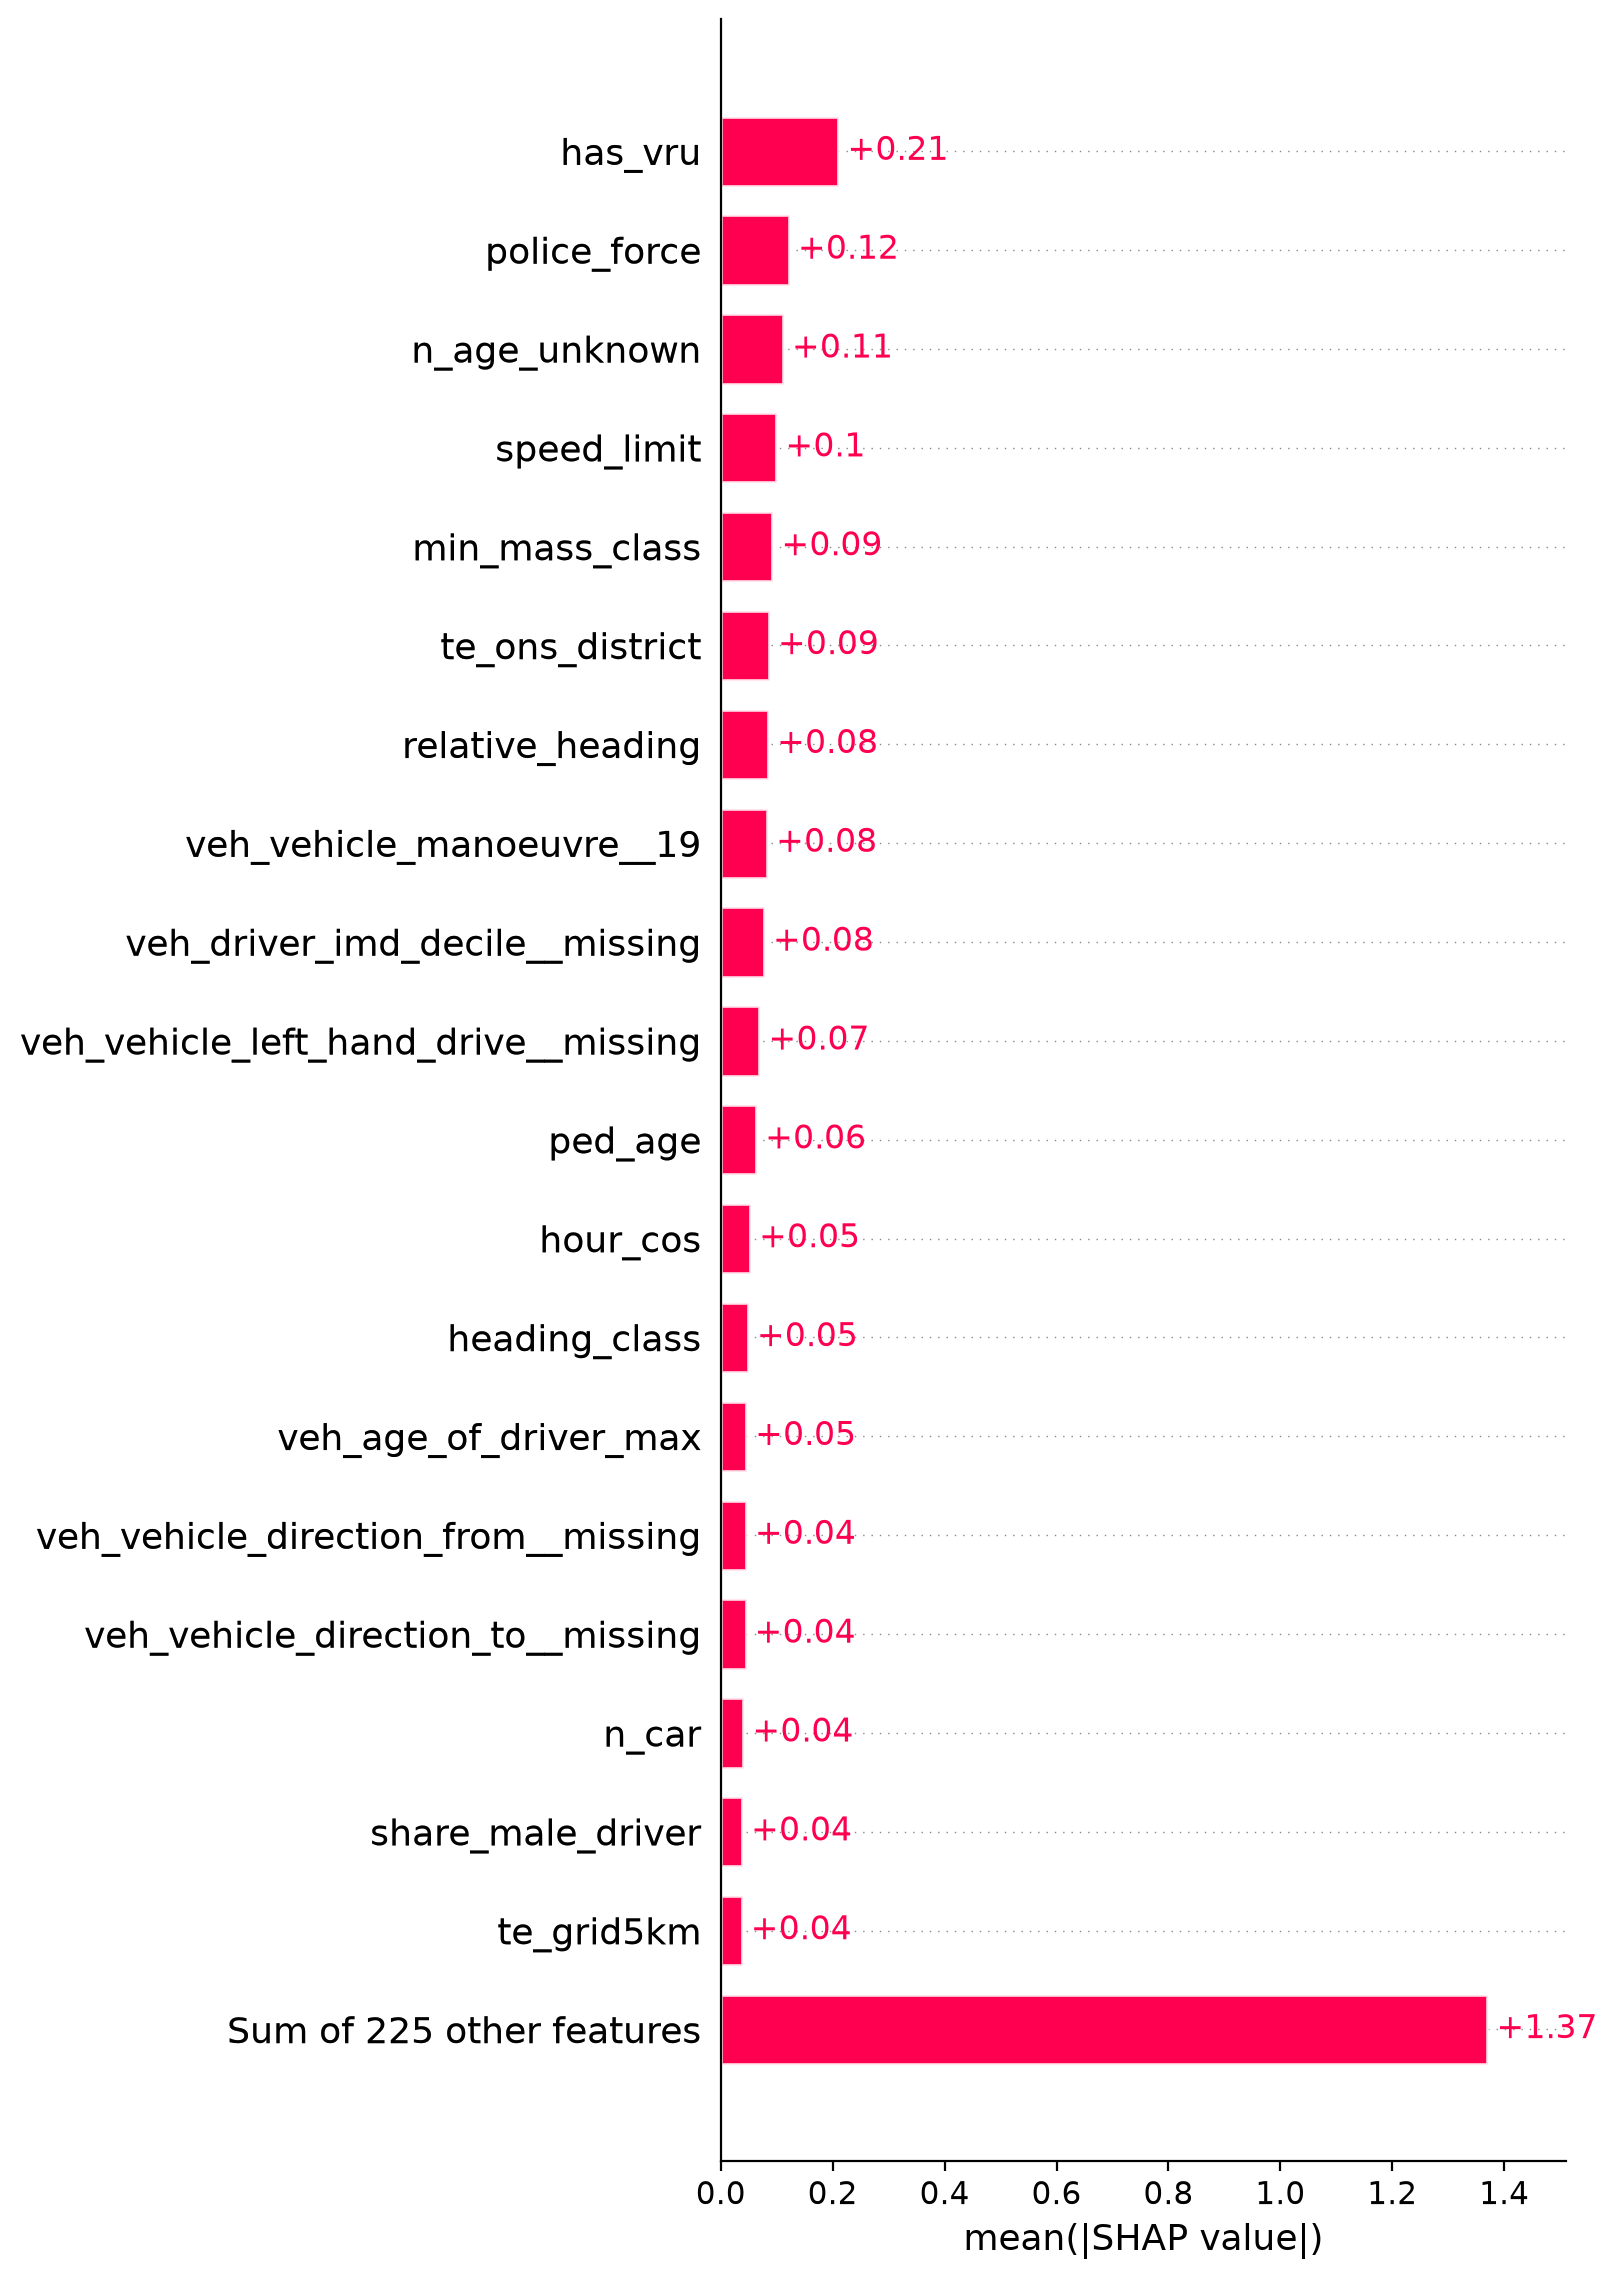

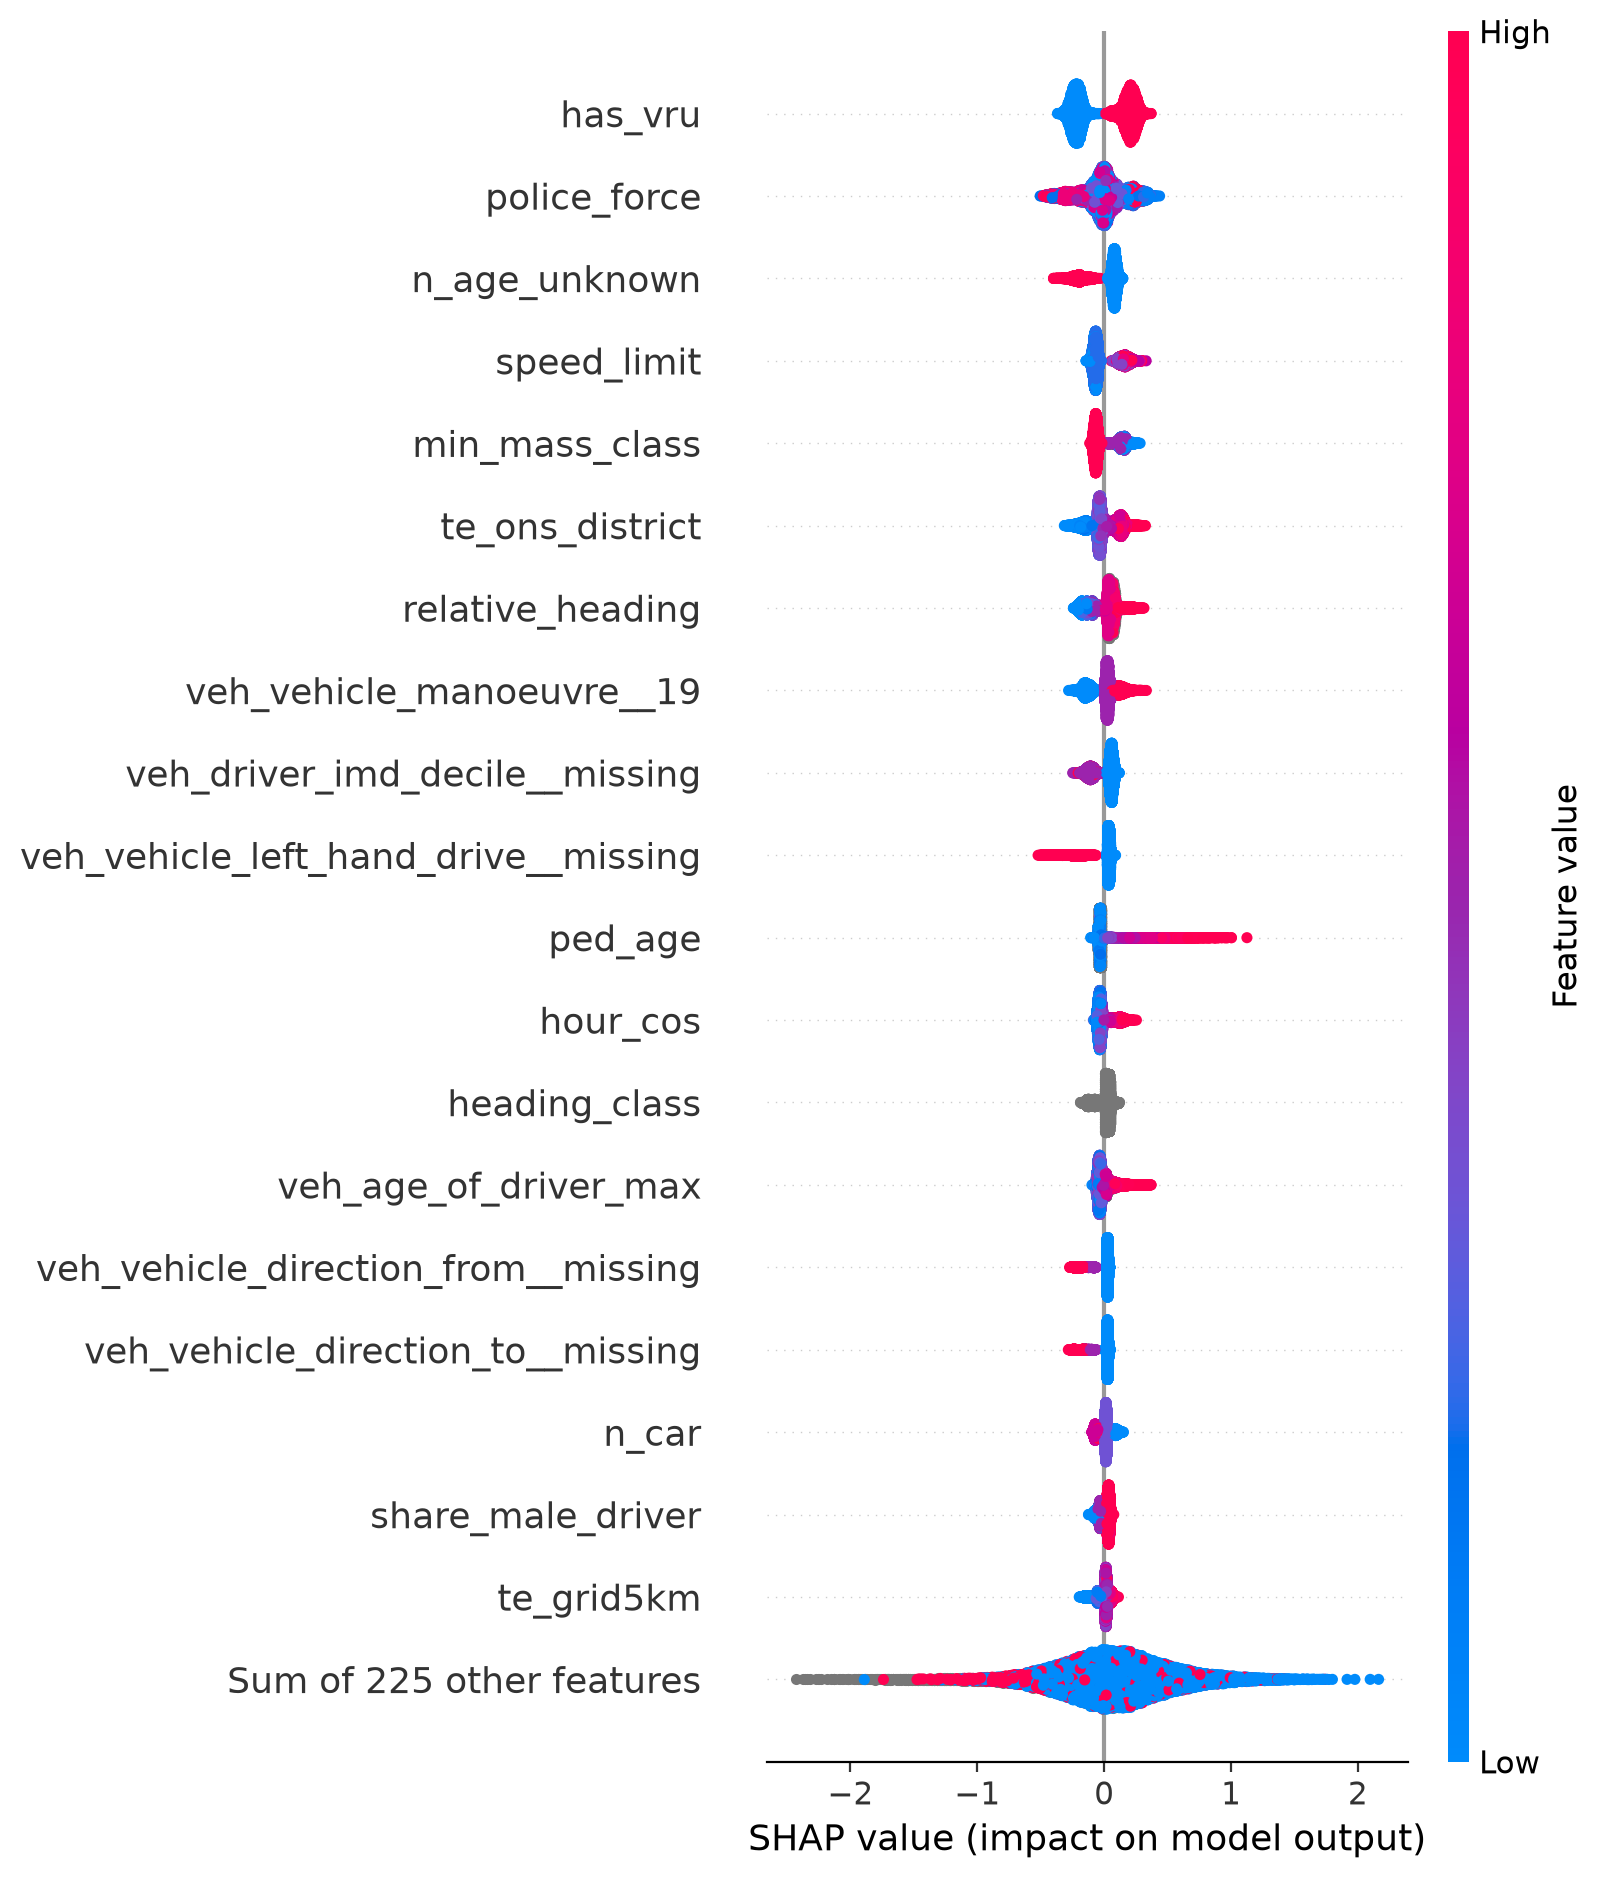

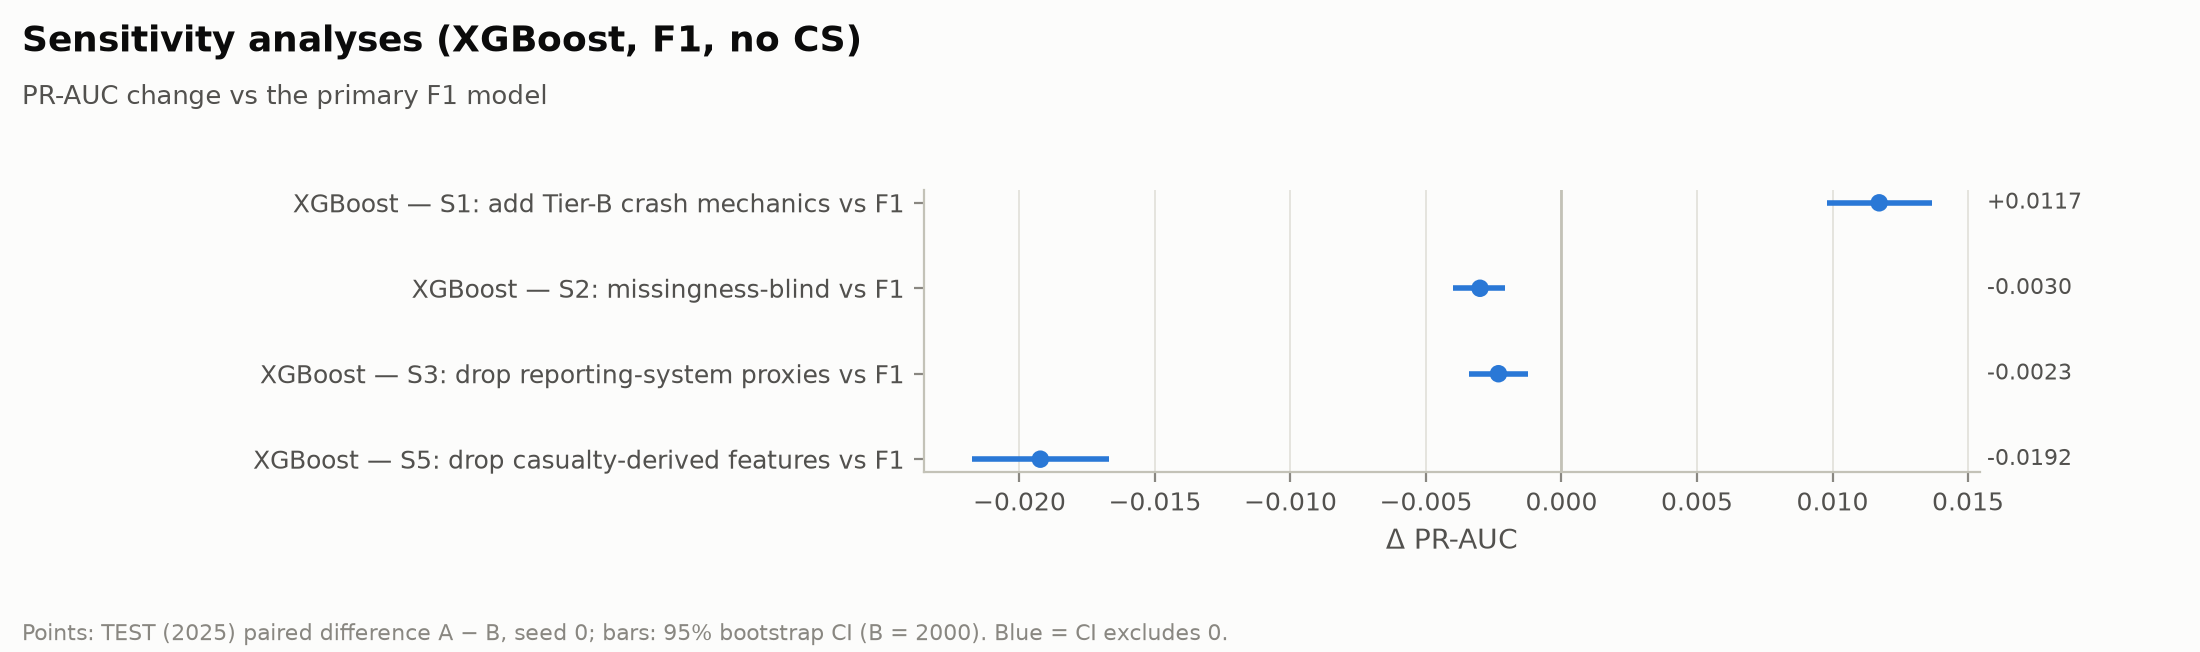

,contrast,pr_auc__a,pr_auc__b,pr_auc__delta,pr_auc__lo,pr_auc__hi,roc_auc__delta,brier__delta
0,S1: add Tier-B crash mechanics vs F1,0.5084,0.4967,0.0117,0.0098,0.0137,0.0078,-0.0019
1,S2: missingness-blind vs F1,0.4937,0.4967,-0.0030,-0.0040,-0.0021,-0.0016,0.0005
2,S3: drop reporting-system proxies vs F1,0.4944,0.4967,-0.0023,-0.0034,-0.0012,-0.0013,0.0004
3,S5: drop casualty-derived features vs F1,0.4775,0.4967,-0.0192,-0.0218,-0.0167,-0.0112,0.0028


,split,n,macro_f1,balanced_accuracy,accuracy,recall_fatal,precision_fatal,f1_fatal,recall_serious,precision_serious,f1_serious,recall_slight,precision_slight,f1_slight
0,cal,49686,0.4538,0.5619,0.6380,0.4584,0.0987,0.1625,0.5622,0.3717,0.4475,0.6651,0.8635,0.7514
1,test,101525,0.4495,0.5539,0.6267,0.4494,0.0965,0.1589,0.5594,0.3774,0.4507,0.6527,0.8513,0.7389


In [10]:
display(pd.read_csv(T / "shap_importance.csv").head(15))
print(json.loads((T / "shap_stability.json").read_text()))
for f in ["shap_bar_test.png", "shap_beeswarm_test.png", "fig_10_sensitivity.png"]:
    if (F / f).exists():
        display(Image(filename=str(F / f), width=800))
for f in ["sensitivity.csv", "sensitivity_s4_multiclass.csv"]:
    if (T / f).exists():
        display(pd.read_csv(T / f))

## 8. Tests
The full pytest suite is run as part of the build (`pytest -q`); the summary is stored in `reports/tables/test_summary.txt`.

In [11]:
p = T / "test_summary.txt"
print(p.read_text() if p.exists() else "run: pytest -q")

157 passed in 7.25s

